## Data Overview

* `Usaha /Produk Utama`: Nama usaha atau produk utama.
* `Total Aset (Rp. Juta)`: Total aset dari seluruh UMKM.
* `Penjualan Rata-rata Per Tahun (Rp. Juta)`: Total penjualan rata-rata UMKM dalam satu tahun.
* `Jumlah Tenaga Kerja`: Jumlah karyawan UMKM.
* `Tahun Survey`: Tahun dilakukannya survei UMKM.
* `Onclick`: URL menuju halaman detail UMKM.
* `Sektor`: Sektor industri UMKM.
* `Nama Badan Hukum`: Tipe badan hukum UMKM.
* `Sistem Penjualan`: Sistem yang digunakan dalam penjualan.
* `Target Pasar Utama: Produk Masal`: Kelompok target massa UMKM dan persentasenya.
* `Target Pasar Utama: Produk Spesifik`: Kelompok target ritel UMKM dan persentasenya.
* `Tingkat Pesaing Usaha`: Kelas pesaing usaha di bidang yang sama.
* `Proyeksi Pertumbuhan Penjualan`: Persentase tingkat pertumbuhan UMKM.
* `Kebutuhan Pembiayaan Kredit`: Nominal yang diinginkan UMKM untuk dipinjam.
* `Nilai Aset yang menjadi jaminan kredit`: Nilai aset yang ingin dijamin oleh UMKM.
* `Jumlah Dokumen Persyaratan Kredit`: Jumlah dokumen persyaratan kredit.
* `Rasio Efisiensi`: Penjualan Rata-rata Per Tahun (Rp. Juta) / Total Aset (Rp. Juta).
* `Rasio Jaminan`: Nilai Aset yang data menjadi jaminan kredit / Kebutuhan Pembiayaan Kredit.
* `Kelayakan`: Kelayakan untuk memperoleh pendanaan (funding).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from sklearn.preprocessing import LabelEncoder
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.preprocessing import StandardScaler
# Menggunakan StandardScaler untuk standardisasi


c:\Users\asus\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [227]:
df = pd.read_csv('train.csv')
df_test_predict = pd.read_csv('test.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 20 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Usaha /Produk Utama                          2606 non-null   object 
 1   Total Aset (Rp. Juta)                        2613 non-null   object 
 2   Penjualan Rata-rata Per Tahun (Rp.Juta)      2612 non-null   object 
 3   Jumlah Tenaga Kerja                          2609 non-null   float64
 4   Tahun Survey                                 2603 non-null   float64
 5   Onclick                                      2603 non-null   object 
 6   Sektor                                       2596 non-null   object 
 7   Nama Badan Hukum                             2599 non-null   object 
 8   Jumlah Tenaga Kerja.1                        2606 non-null   float64
 9   Sistem Penjualan                             2605 non-null   object 
 10  

In [4]:
df.head()

,Usaha /Produk Utama,Total Aset (Rp. Juta),Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Onclick,Sektor,Nama Badan Hukum,Jumlah Tenaga Kerja.1,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Total Aset,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan
0,Pembuatan Gorden,76,340,7.0,2008.0,?pm=j59nIvMETsw7u5JMLGk/hA==&mp=LhrIHvxx5uWPOv...,Industri Pengolahan,Perorangan,7.0,Retail,"Tidak Ada ÃÂ 0,00ÃÂ %",Masyarakat Golongan Menengah (penghasilan Rp 5...,Sedang,"Rp. 76,00 Juta","Rp. 340,00 Juta",15 %/Tahun,"Rp. 0,00 Juta","Rp. 250,00 Juta",10.0,yes
1,Warung,87,384,1.0,2011.0,?pm=NWRRNiCMs9Gm3yfiV7Bmlg==&mp=Bjv3m4lcInn46O...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,1.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,"Rp. 87,00 Juta","Rp. 384,00 Juta",20 %/Tahun,"Rp. 10,00 Juta","Rp. 33,00 Juta",6.0,no
2,Dagang Ikan,"1,5",201,1.0,2010.0,?pm=mThCtpx97KnuiRt0tdnrgg==&mp=JHuIBacQ7Iz+a8...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,1.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,"Rp. 1,50 Juta","Rp. 201,00 Juta",20 %/Tahun,"Rp. 10,00 Juta","Rp. 287,00 Juta",6.0,no
3,Toko,320,180,2.0,2013.0,?pm=knHAJisASl62UpOvjBL2uA==&mp=fOhzApotY5QnAt...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,2.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Tinggi,"Rp. 320,00 Juta","Rp. 180,00 Juta",10 %/Tahun,"Rp. 10,00 Juta","Rp. 7,00 Juta",4.0,no
4,Petani Padi,33,20,1.0,2012.0,?pm=o9ox3asJi41BzF/lO3rO6Q==&mp=p1ca+Y2BZCwOZV...,"Pertanian, Kehutanan, dan Perikanan",Perorangan,1.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada 0,00 %",Rendah,"Rp. 33,00 Juta","Rp. 20,00 Juta",20 %/Tahun,"Rp. 2,00 Juta","Rp. 36,00 Juta",3.0,no


In [5]:
df.tail()

,Usaha /Produk Utama,Total Aset (Rp. Juta),Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Onclick,Sektor,Nama Badan Hukum,Jumlah Tenaga Kerja.1,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Total Aset,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan
2639,Dagang Topi Dan Aksesoris Sekolah,"25,6",58,1.0,2010.0,?pm=vTKz7d/WGhSXoITNLJ62qw==&mp=JHuIBacQ7Iz+a8...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,1.0,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Rendah,"Rp. 25,60 Juta","Rp. 58,00 Juta",10 %/Tahun,"Rp. 6,00 Juta","Rp. 119,00 Juta",5.0,no
2640,Toko Serba Ada,1.597,4.950,14.0,2013.0,?pm=HA7b5rAGXw5aTaqv2Iq71A==&mp=fOhzApotY5QnAt...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,14.0,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,"Rp. 1.597,00 Juta","Rp. 4.950,00 Juta",30 %/Tahun,"Rp. 0,00 Juta","Rp. 250,00 Juta",11.0,no
2641,Pembuatan Sapu Ijuk Dan Pel,26.600.000,324,1.0,2011.0,?pm=qZPPBWy6F/6YwilYyeTFdg==&mp=Bjv3m4lcInn46O...,Industri Pengolahan,Perorangan,1.0,Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂ 0,00ÃÂ %",Tinggi,"Rp. 26.600.000,00 Juta","Rp. 324,00 Juta",25 %/Tahun,"Rp. 9,00 Juta","Rp. 14,00 Juta",5.0,no
2642,Dagang Sembako,"89,5",74,2.0,2011.0,?pm=Hn/qJmIKh5G/m9T6TmshiA==&mp=Bjv3m4lcInn46O...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,2.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,"Rp. 89,50 Juta","Rp. 74,00 Juta",5 %/Tahun,"Rp. 0,00 Juta","Rp. 80,00 Juta",4.0,no
2643,Celuller,"79,4",48,1.0,2013.0,?pm=s1gx7slYZUFHlFgwvYuvZA==&mp=fOhzApotY5QnAt...,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,1.0,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Tinggi,"Rp. 79,40 Juta","Rp. 48,00 Juta",10 %/Tahun,"Rp. 10,00 Juta","Rp. 103,00 Juta",6.0,no


In [6]:
df.nunique()

Usaha /Produk Utama                             790
Total Aset (Rp. Juta)                           789
Penjualan Rata-rata Per Tahun (Rp.Juta)         511
Jumlah Tenaga Kerja                              32
Tahun Survey                                      8
Onclick                                        1244
Sektor                                           13
Nama Badan Hukum                                  4
Jumlah Tenaga Kerja.1                            32
Sistem Penjualan                                  4
Target Pasar Utama : Produk Masal               101
Target Pasar Utama : Produk Spesifik            109
Tingkat Pesaing Usaha                             3
Total Aset                                      789
Penjualan Rata-Rata per Tahun                   514
Proyeksi Pertumbuhan Penjualan                   41
Kebutuhan Pembiayaan Kredit                      11
Nilai Aset yang data menjadi jaminan kredit     261
Jumlah Dokumen Persyaratan Kredit                12
Kelayakan   

In [7]:
df.isna().sum()

Usaha /Produk Utama                            38
Total Aset (Rp. Juta)                          31
Penjualan Rata-rata Per Tahun (Rp.Juta)        32
Jumlah Tenaga Kerja                            35
Tahun Survey                                   41
Onclick                                        41
Sektor                                         48
Nama Badan Hukum                               45
Jumlah Tenaga Kerja.1                          38
Sistem Penjualan                               39
Target Pasar Utama : Produk Masal              43
Target Pasar Utama : Produk Spesifik           28
Tingkat Pesaing Usaha                          44
Total Aset                                     39
Penjualan Rata-Rata per Tahun                  38
Proyeksi Pertumbuhan Penjualan                 41
Kebutuhan Pembiayaan Kredit                    39
Nilai Aset yang data menjadi jaminan kredit    42
Jumlah Dokumen Persyaratan Kredit              29
Kelayakan                                      43


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Jumlah Tenaga Kerja,2609.0,3.543887,5.173198,0.0,1.0,2.0,4.0,109.0
Tahun Survey,2603.0,2010.801383,25.097353,2008.0,2008.0,2010.0,2012.0,2913.0
Jumlah Tenaga Kerja.1,2606.0,3.543361,5.176152,0.0,1.0,2.0,4.0,109.0
Jumlah Dokumen Persyaratan Kredit,2615.0,4.843977,1.547556,0.0,4.0,5.0,6.0,11.0


### Exploratory Data Analytics (EDA)

In [9]:
cat_cols=df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['Usaha /Produk Utama', 'Total Aset (Rp. Juta)', 'Penjualan Rata-rata Per Tahun (Rp.Juta)', 'Onclick', 'Sektor', 'Nama Badan Hukum', 'Sistem Penjualan', 'Target Pasar Utama : Produk Masal', 'Target Pasar Utama : Produk Spesifik', 'Tingkat Pesaing Usaha', 'Total Aset', 'Penjualan Rata-Rata per Tahun', 'Proyeksi Pertumbuhan Penjualan', 'Kebutuhan Pembiayaan Kredit ', 'Nilai Aset yang data menjadi jaminan kredit', 'Kelayakan']
Numerical Variables:
['Jumlah Tenaga Kerja', 'Tahun Survey', 'Jumlah Tenaga Kerja.1', 'Jumlah Dokumen Persyaratan Kredit']


Jumlah Tenaga Kerja
Skew : 9.03


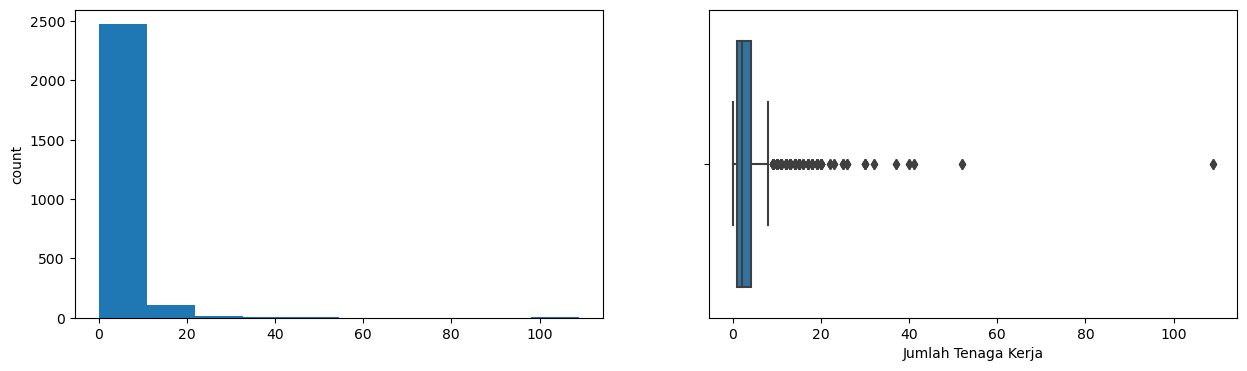

Tahun Survey
Skew : 35.73


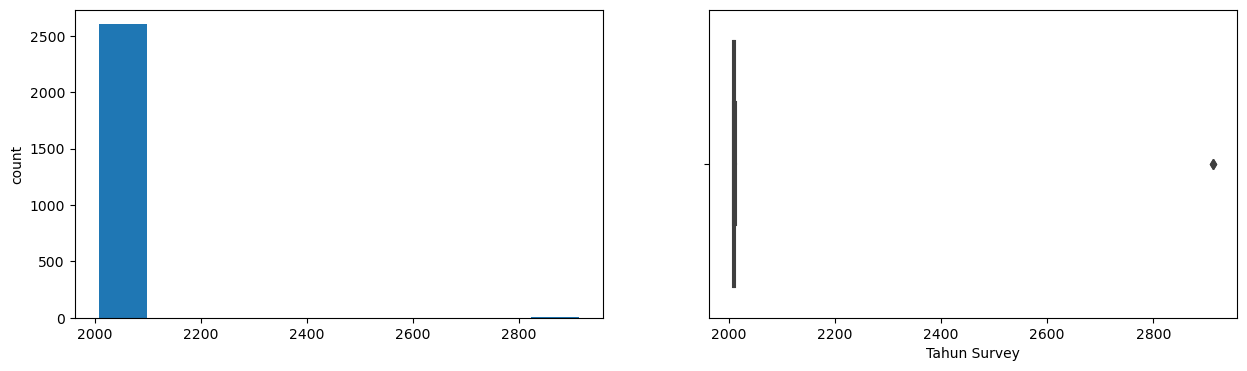

Jumlah Tenaga Kerja.1
Skew : 9.02


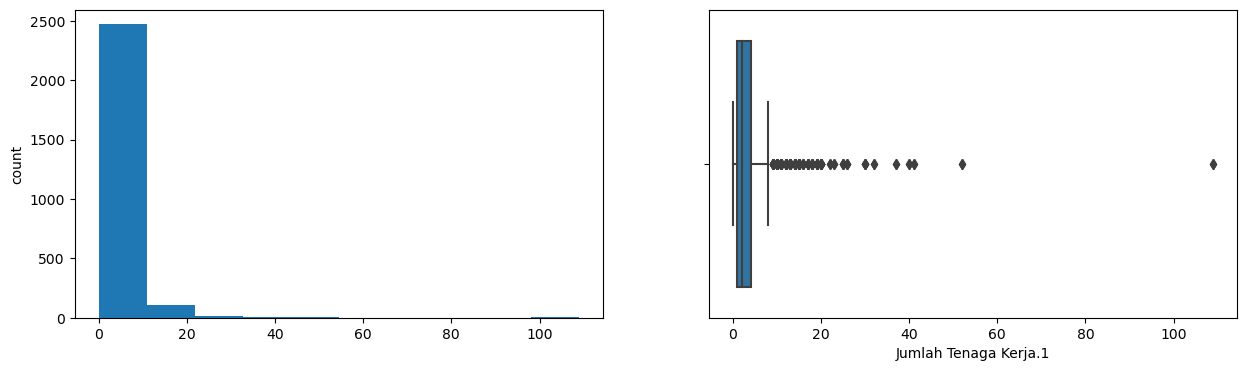

Jumlah Dokumen Persyaratan Kredit
Skew : 0.34


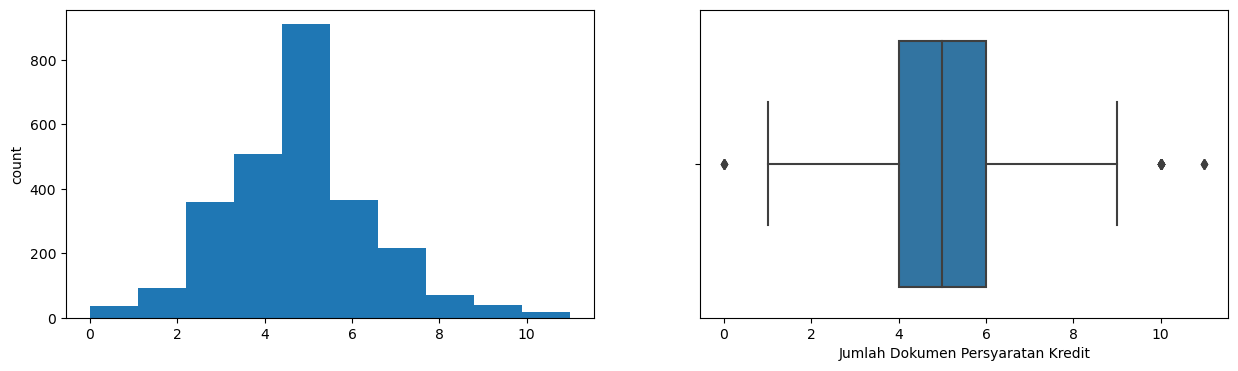

In [10]:
for col in num_cols:
    print(col)
    print('Skew :', round(df[col].skew(), 2))
    plt.figure(figsize = (15, 4))
    plt.subplot(1, 2, 1)
    df[col].hist(grid=False)
    plt.ylabel('count')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col])
    plt.show()

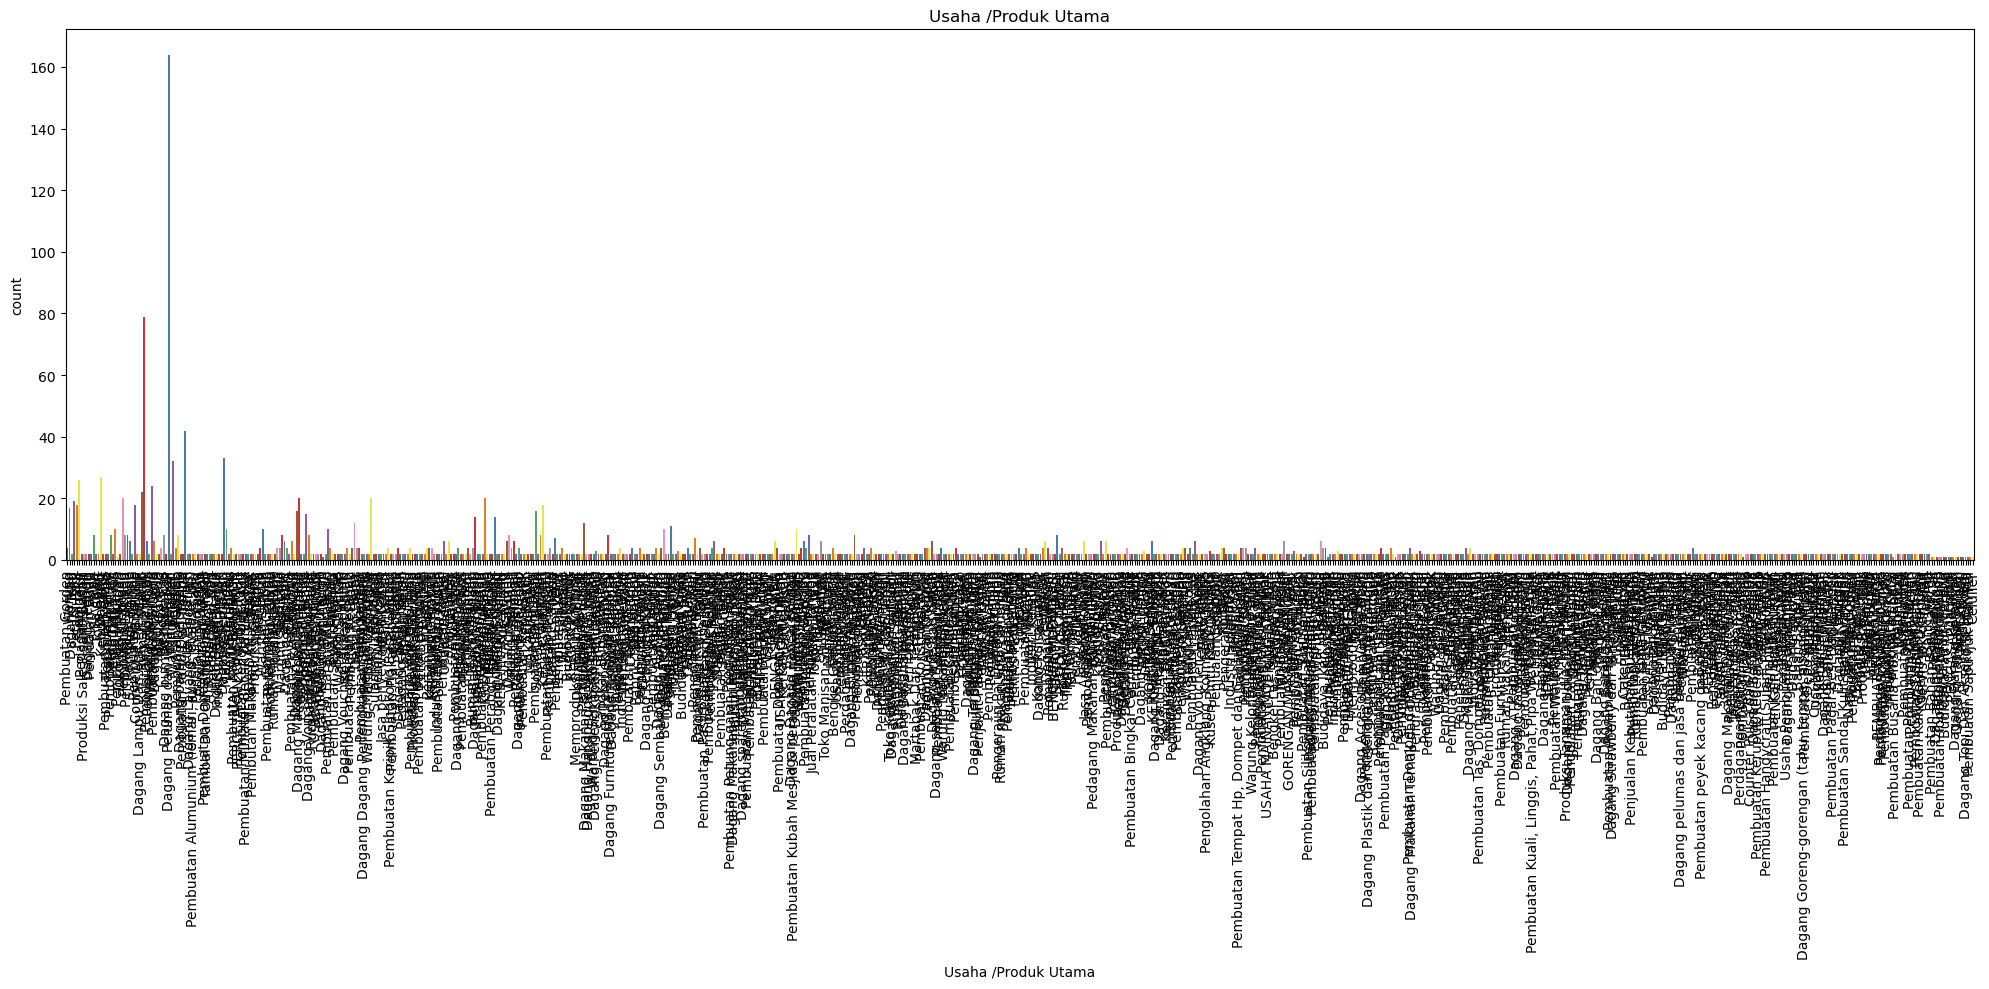

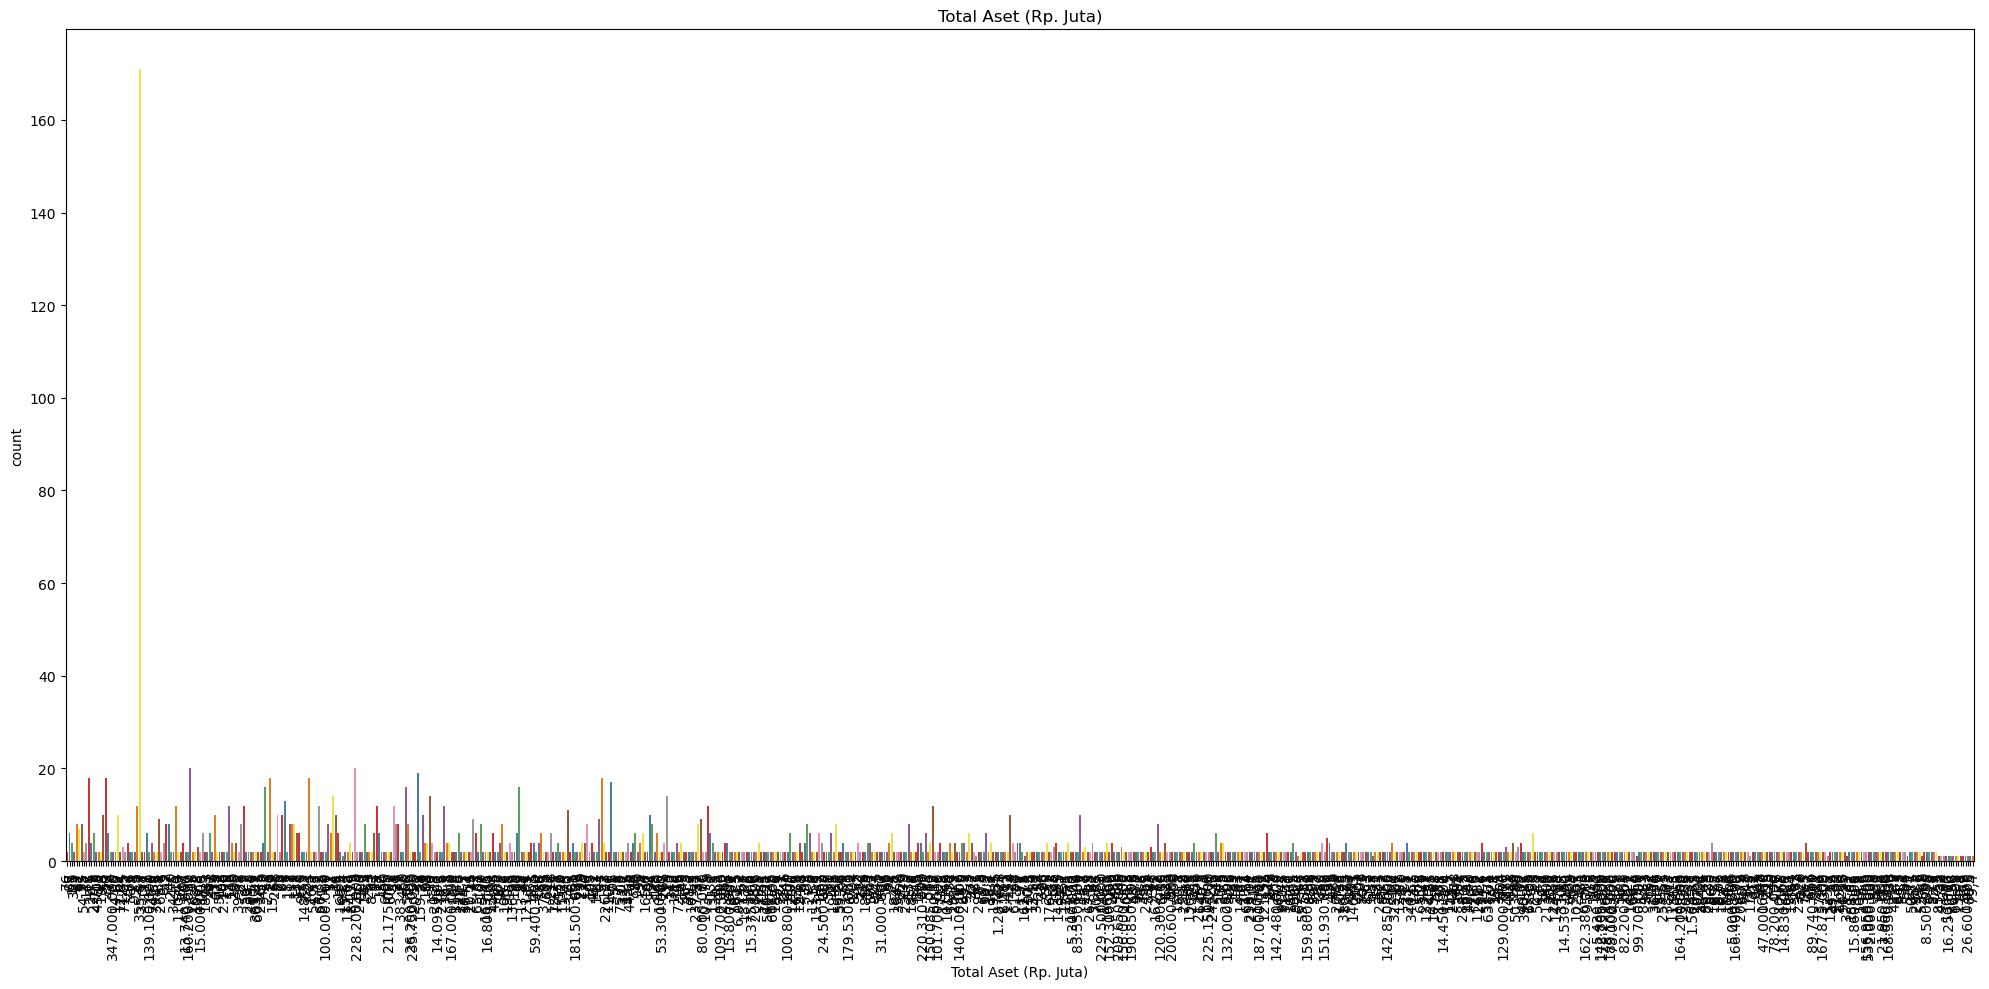

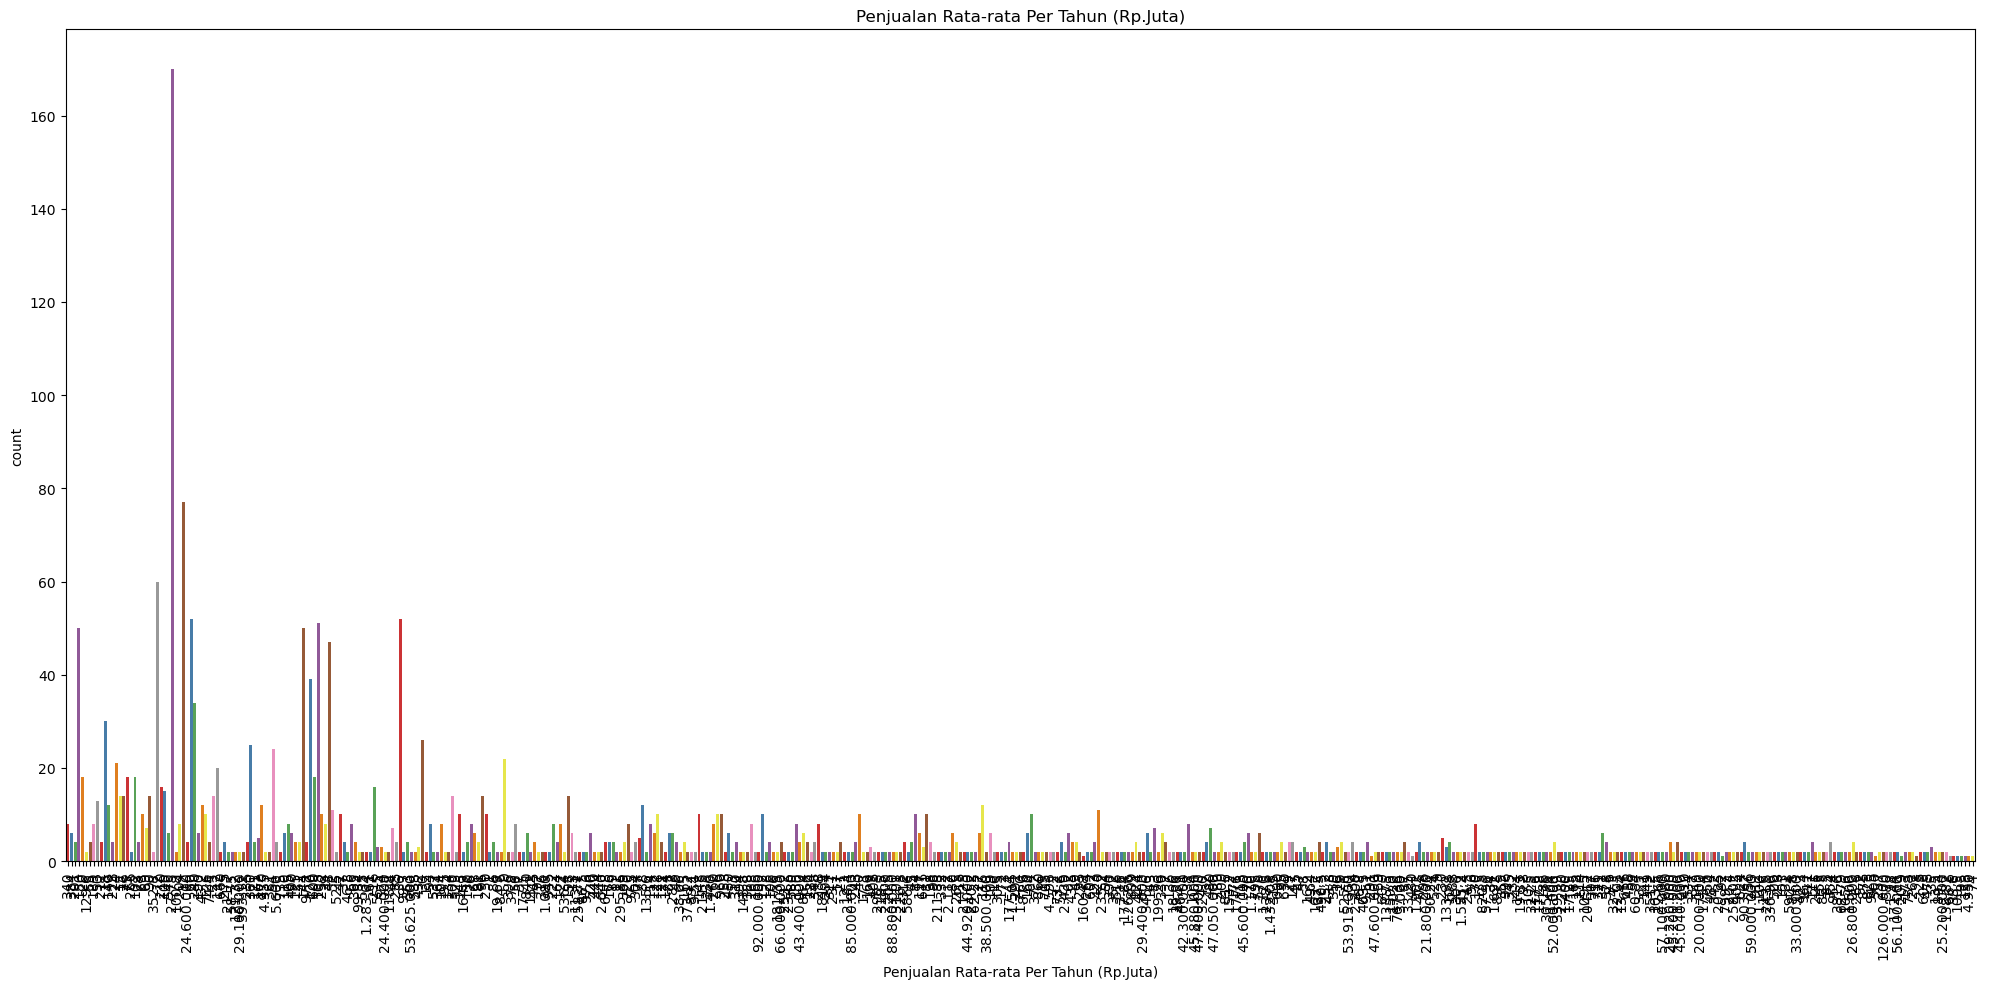

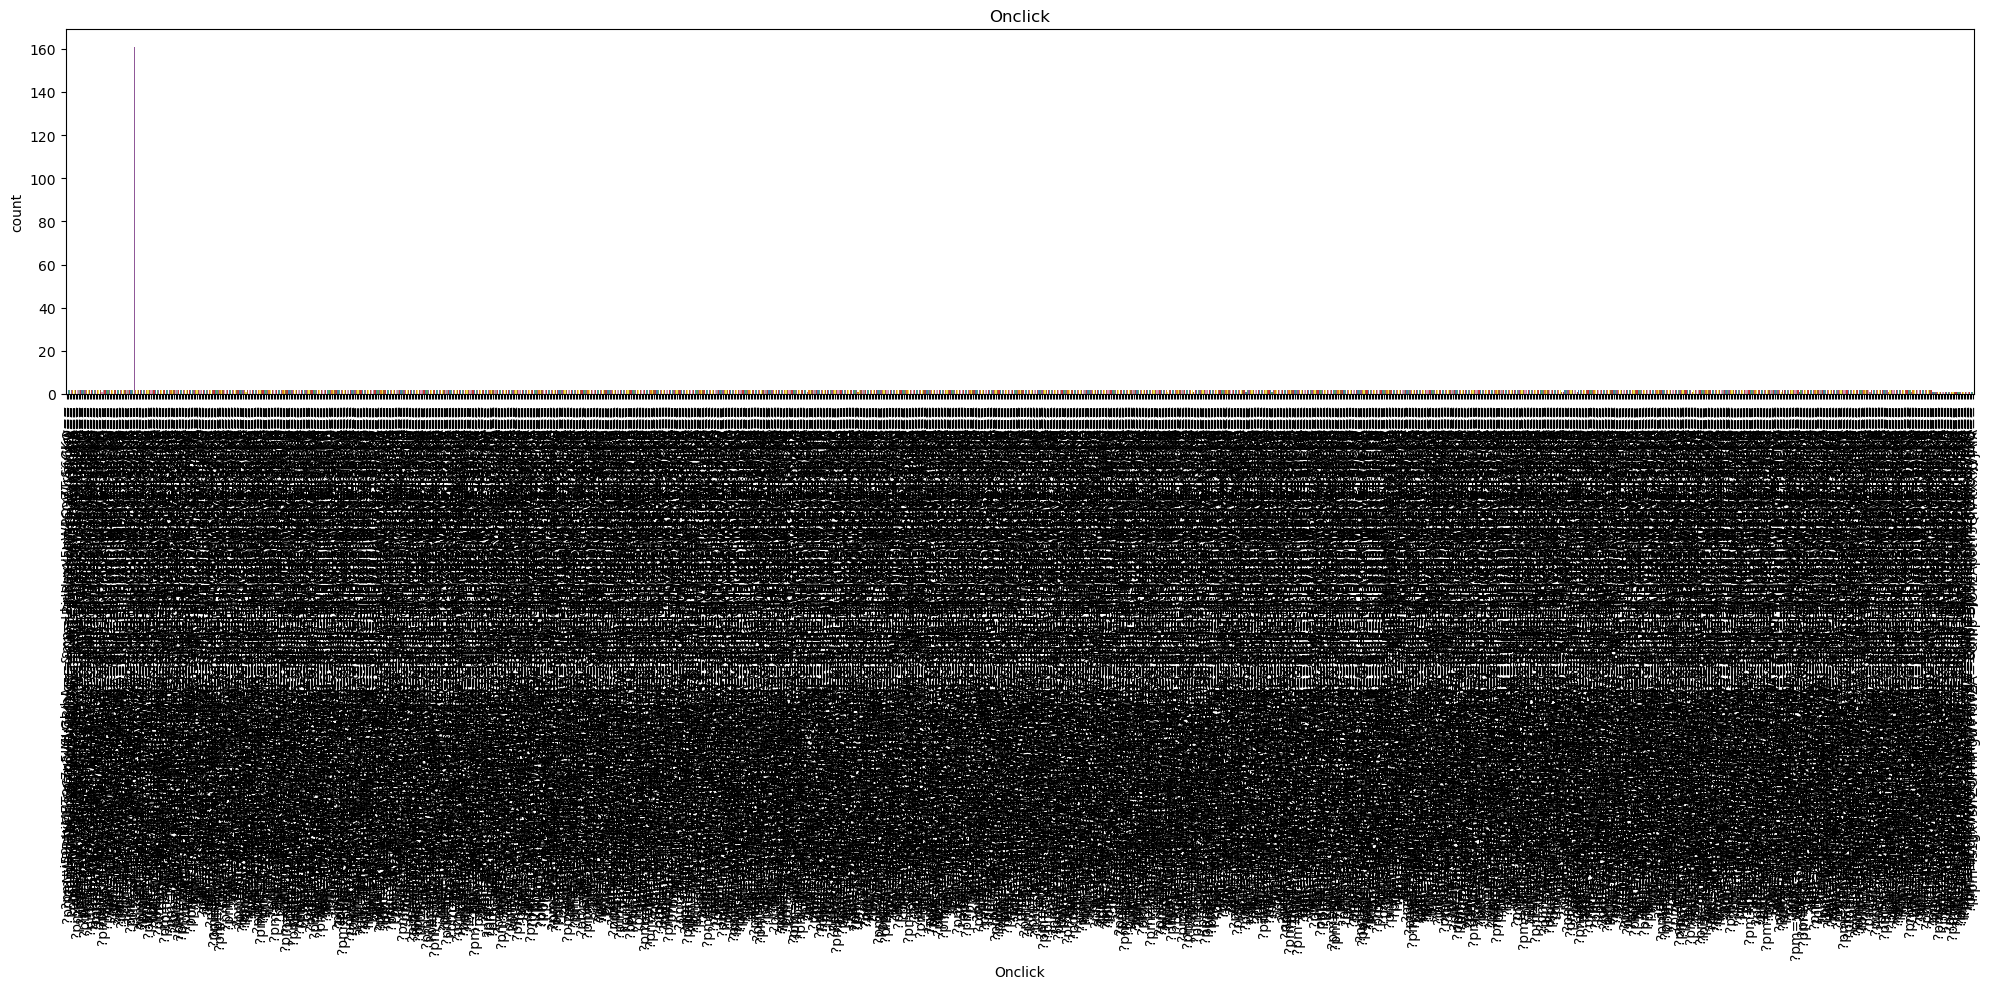

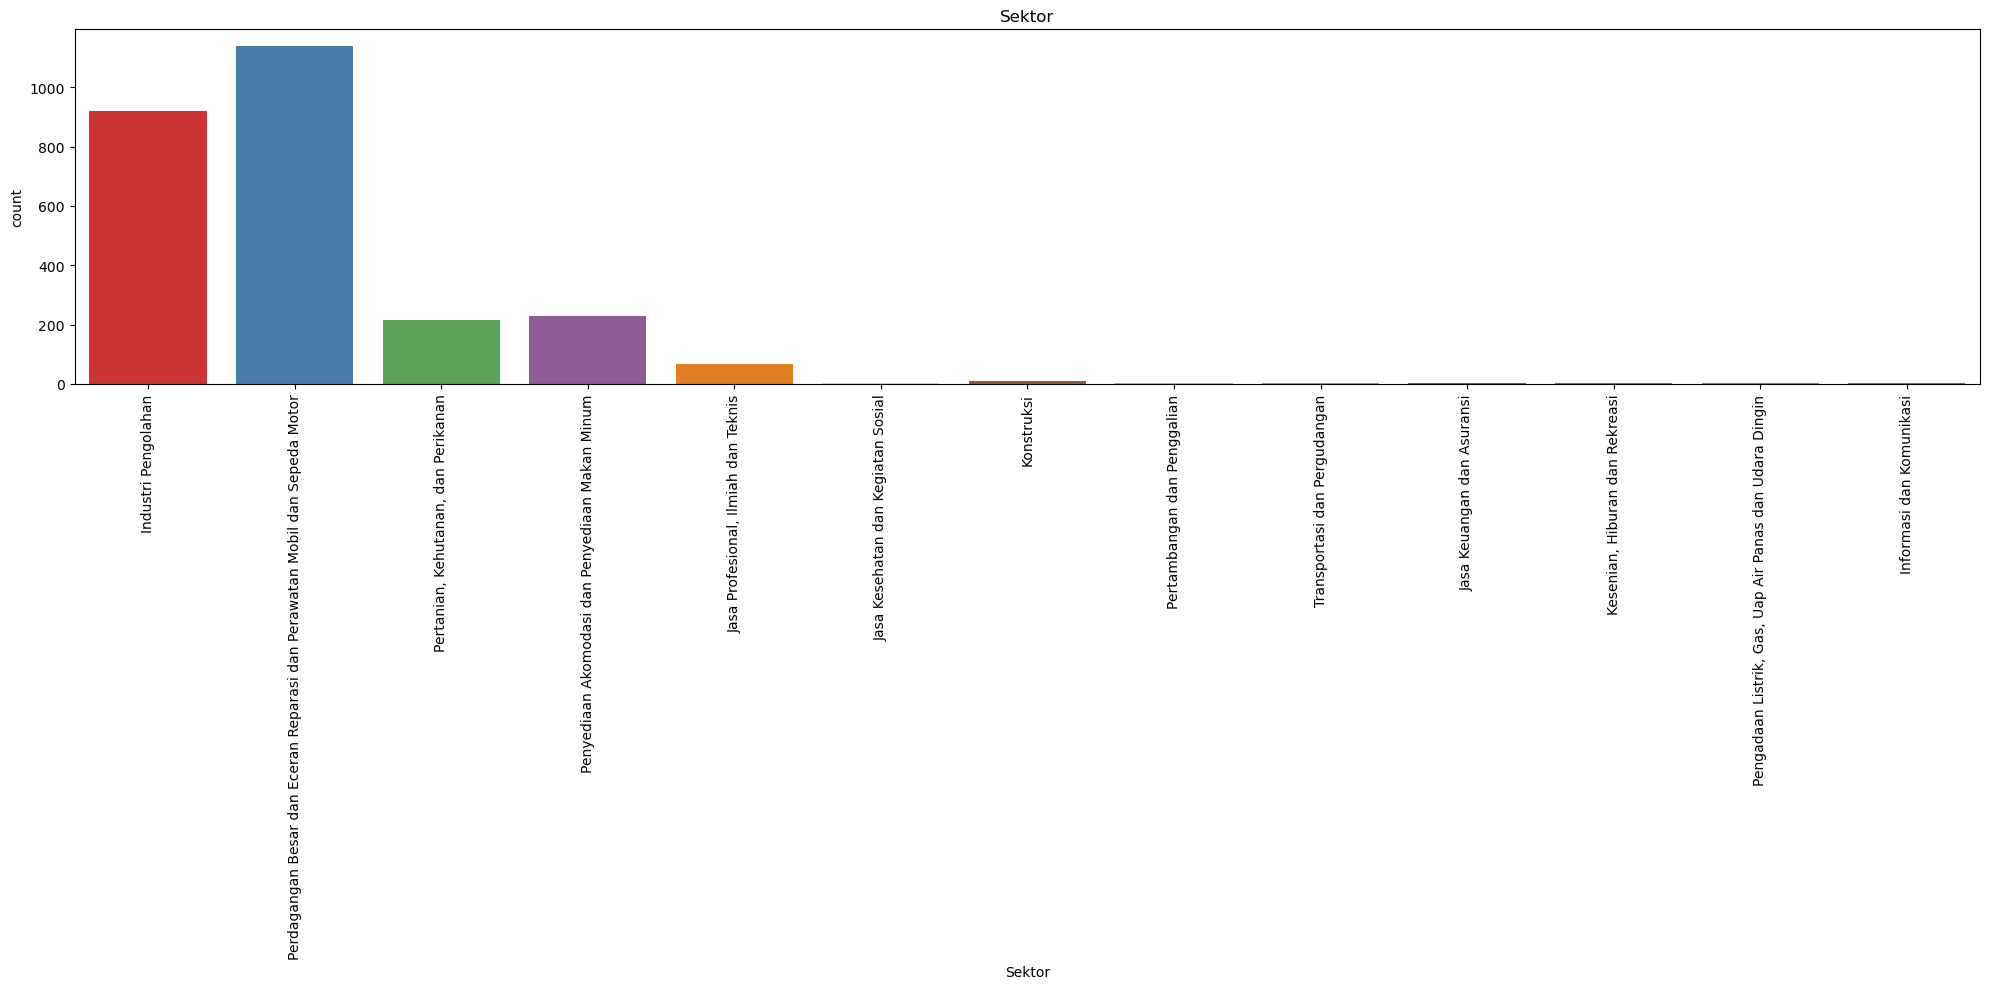

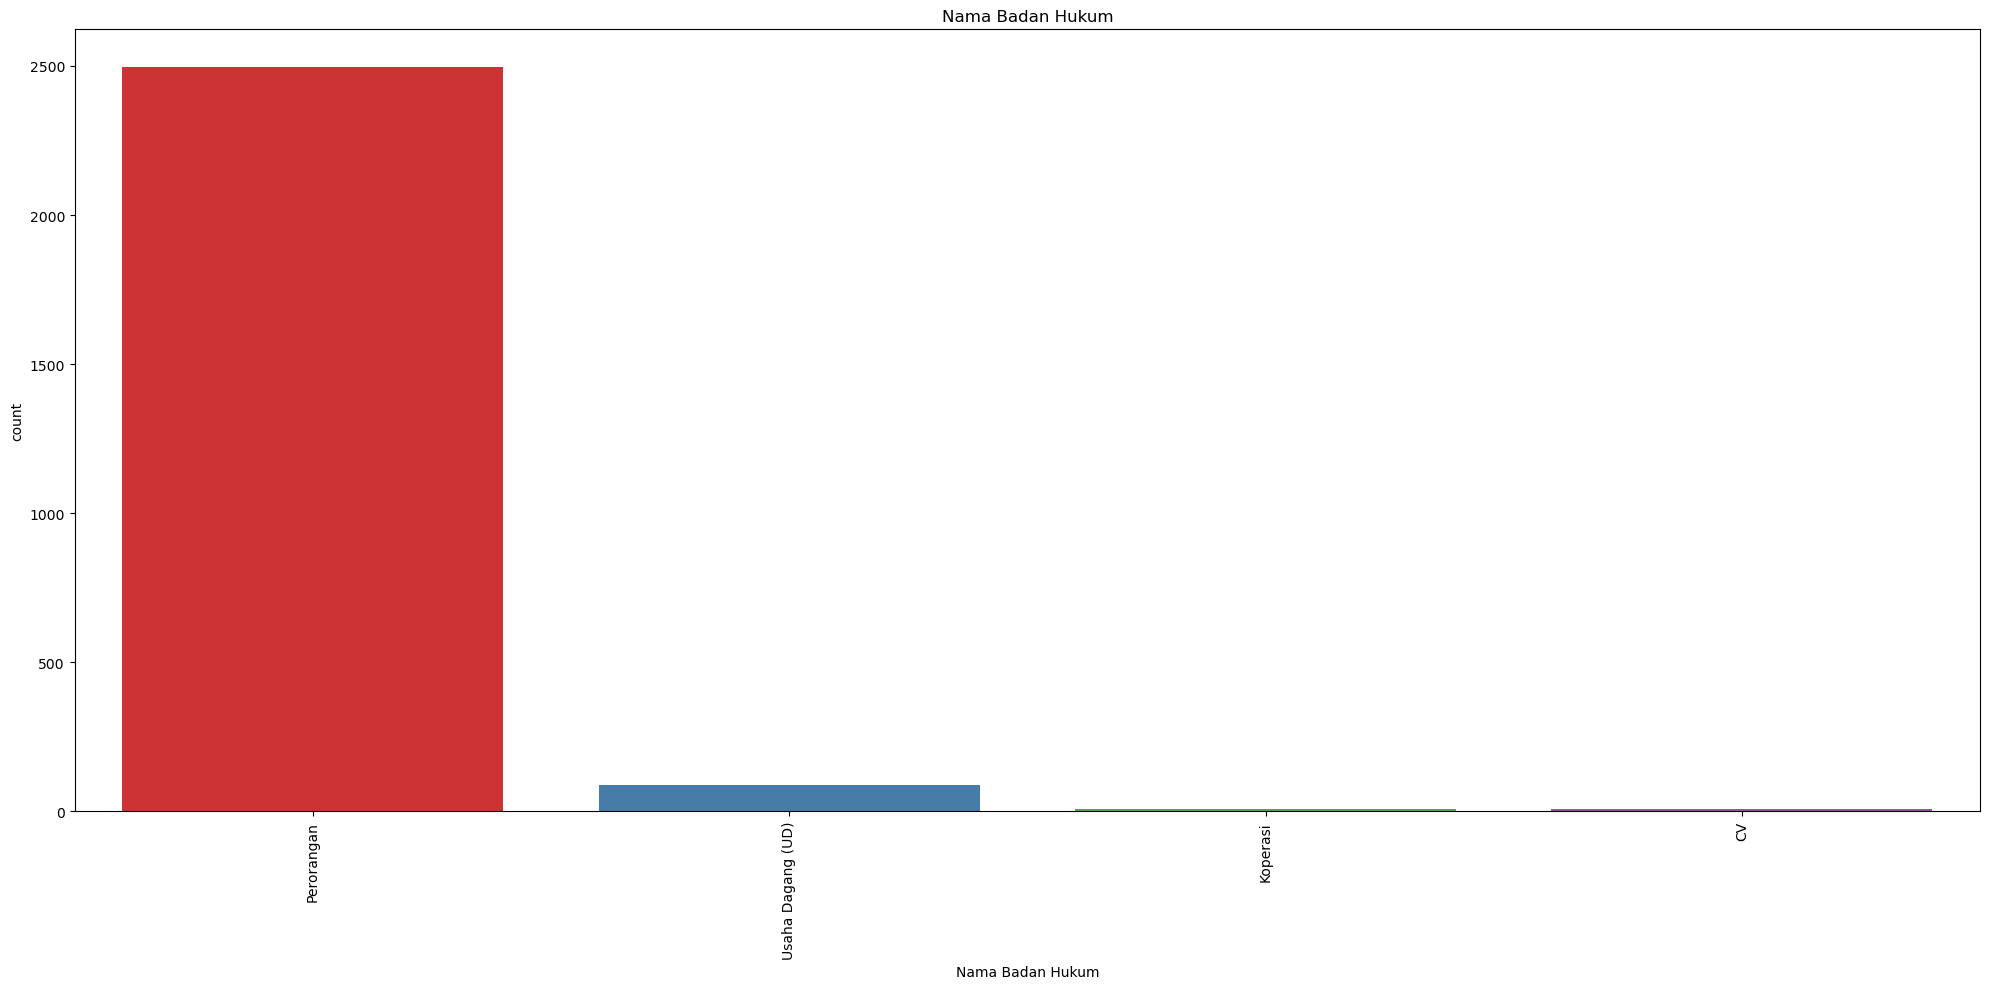

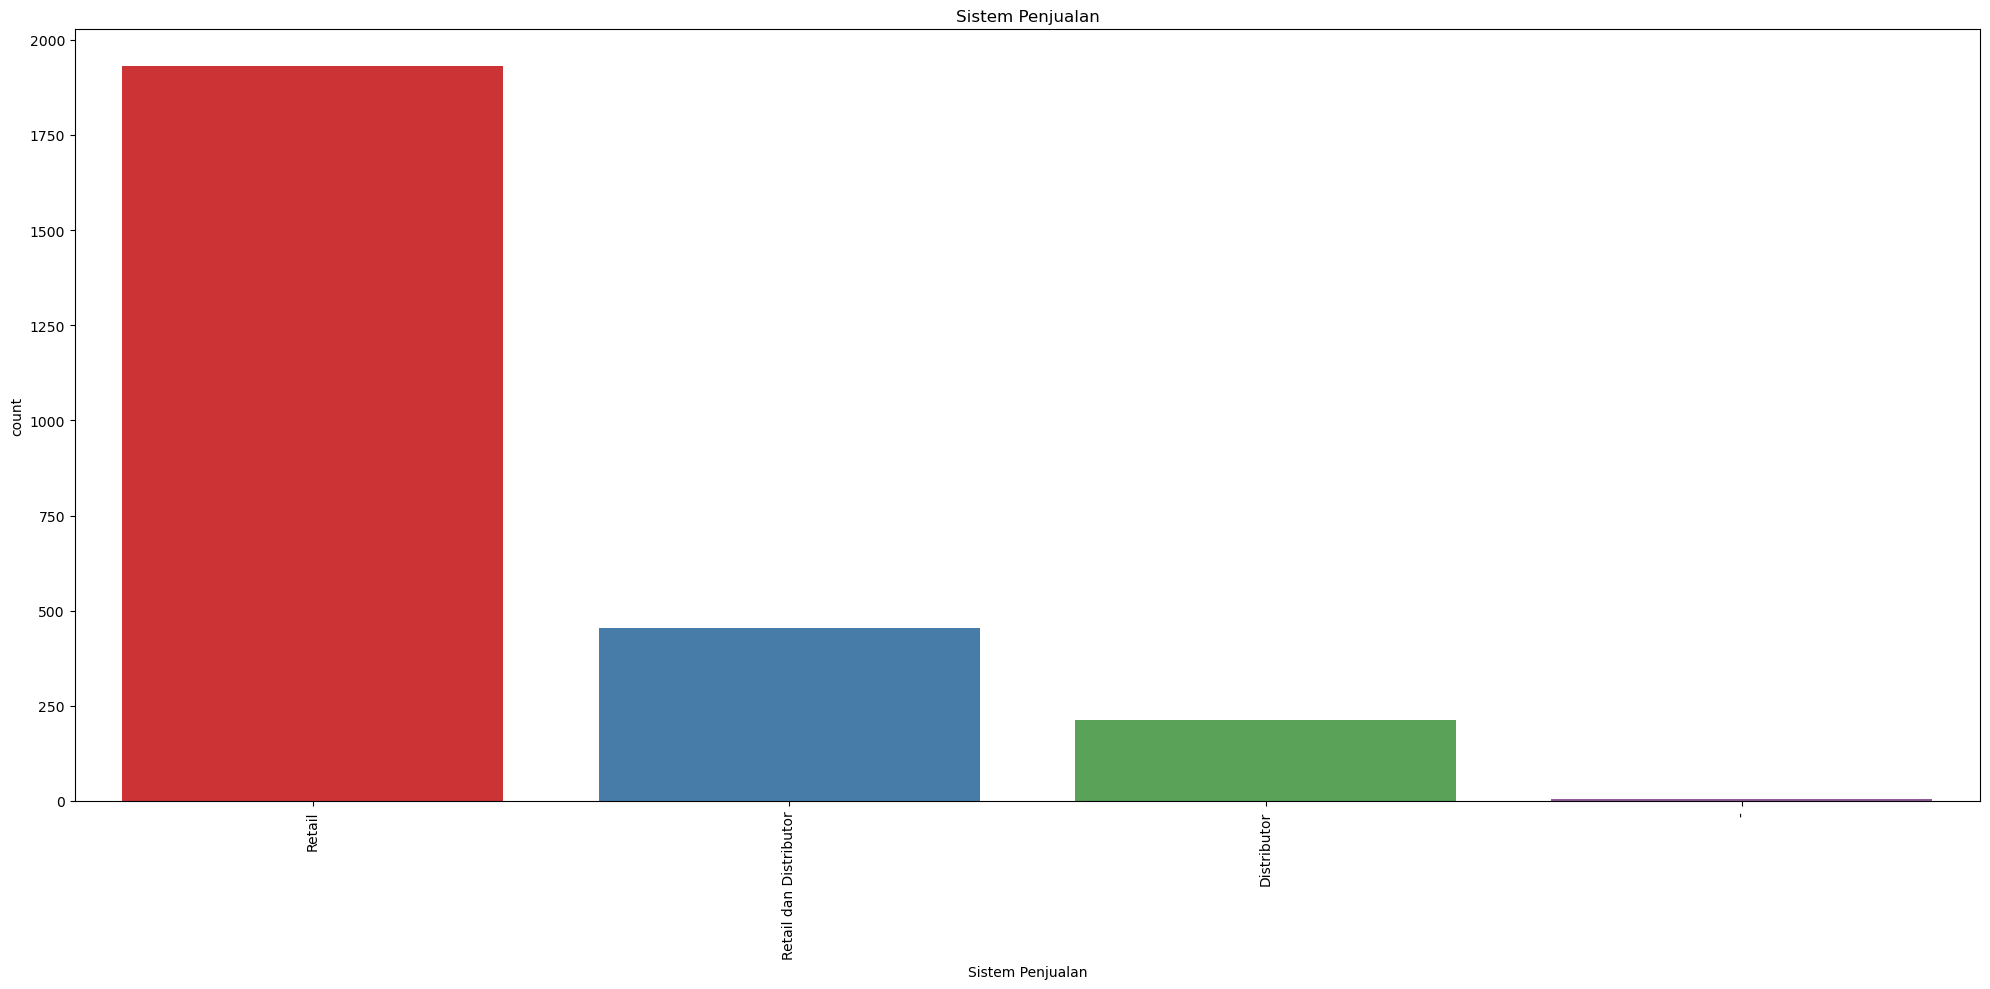

C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Glyph 130 (\x82) missing from current font.
  plt.tight_layout()
C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Glyph 131 (\x83) missing from current font.
  plt.tight_layout()
C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
c:\Users\asus\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 130 (\x82) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\asus\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 131 (\x83) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


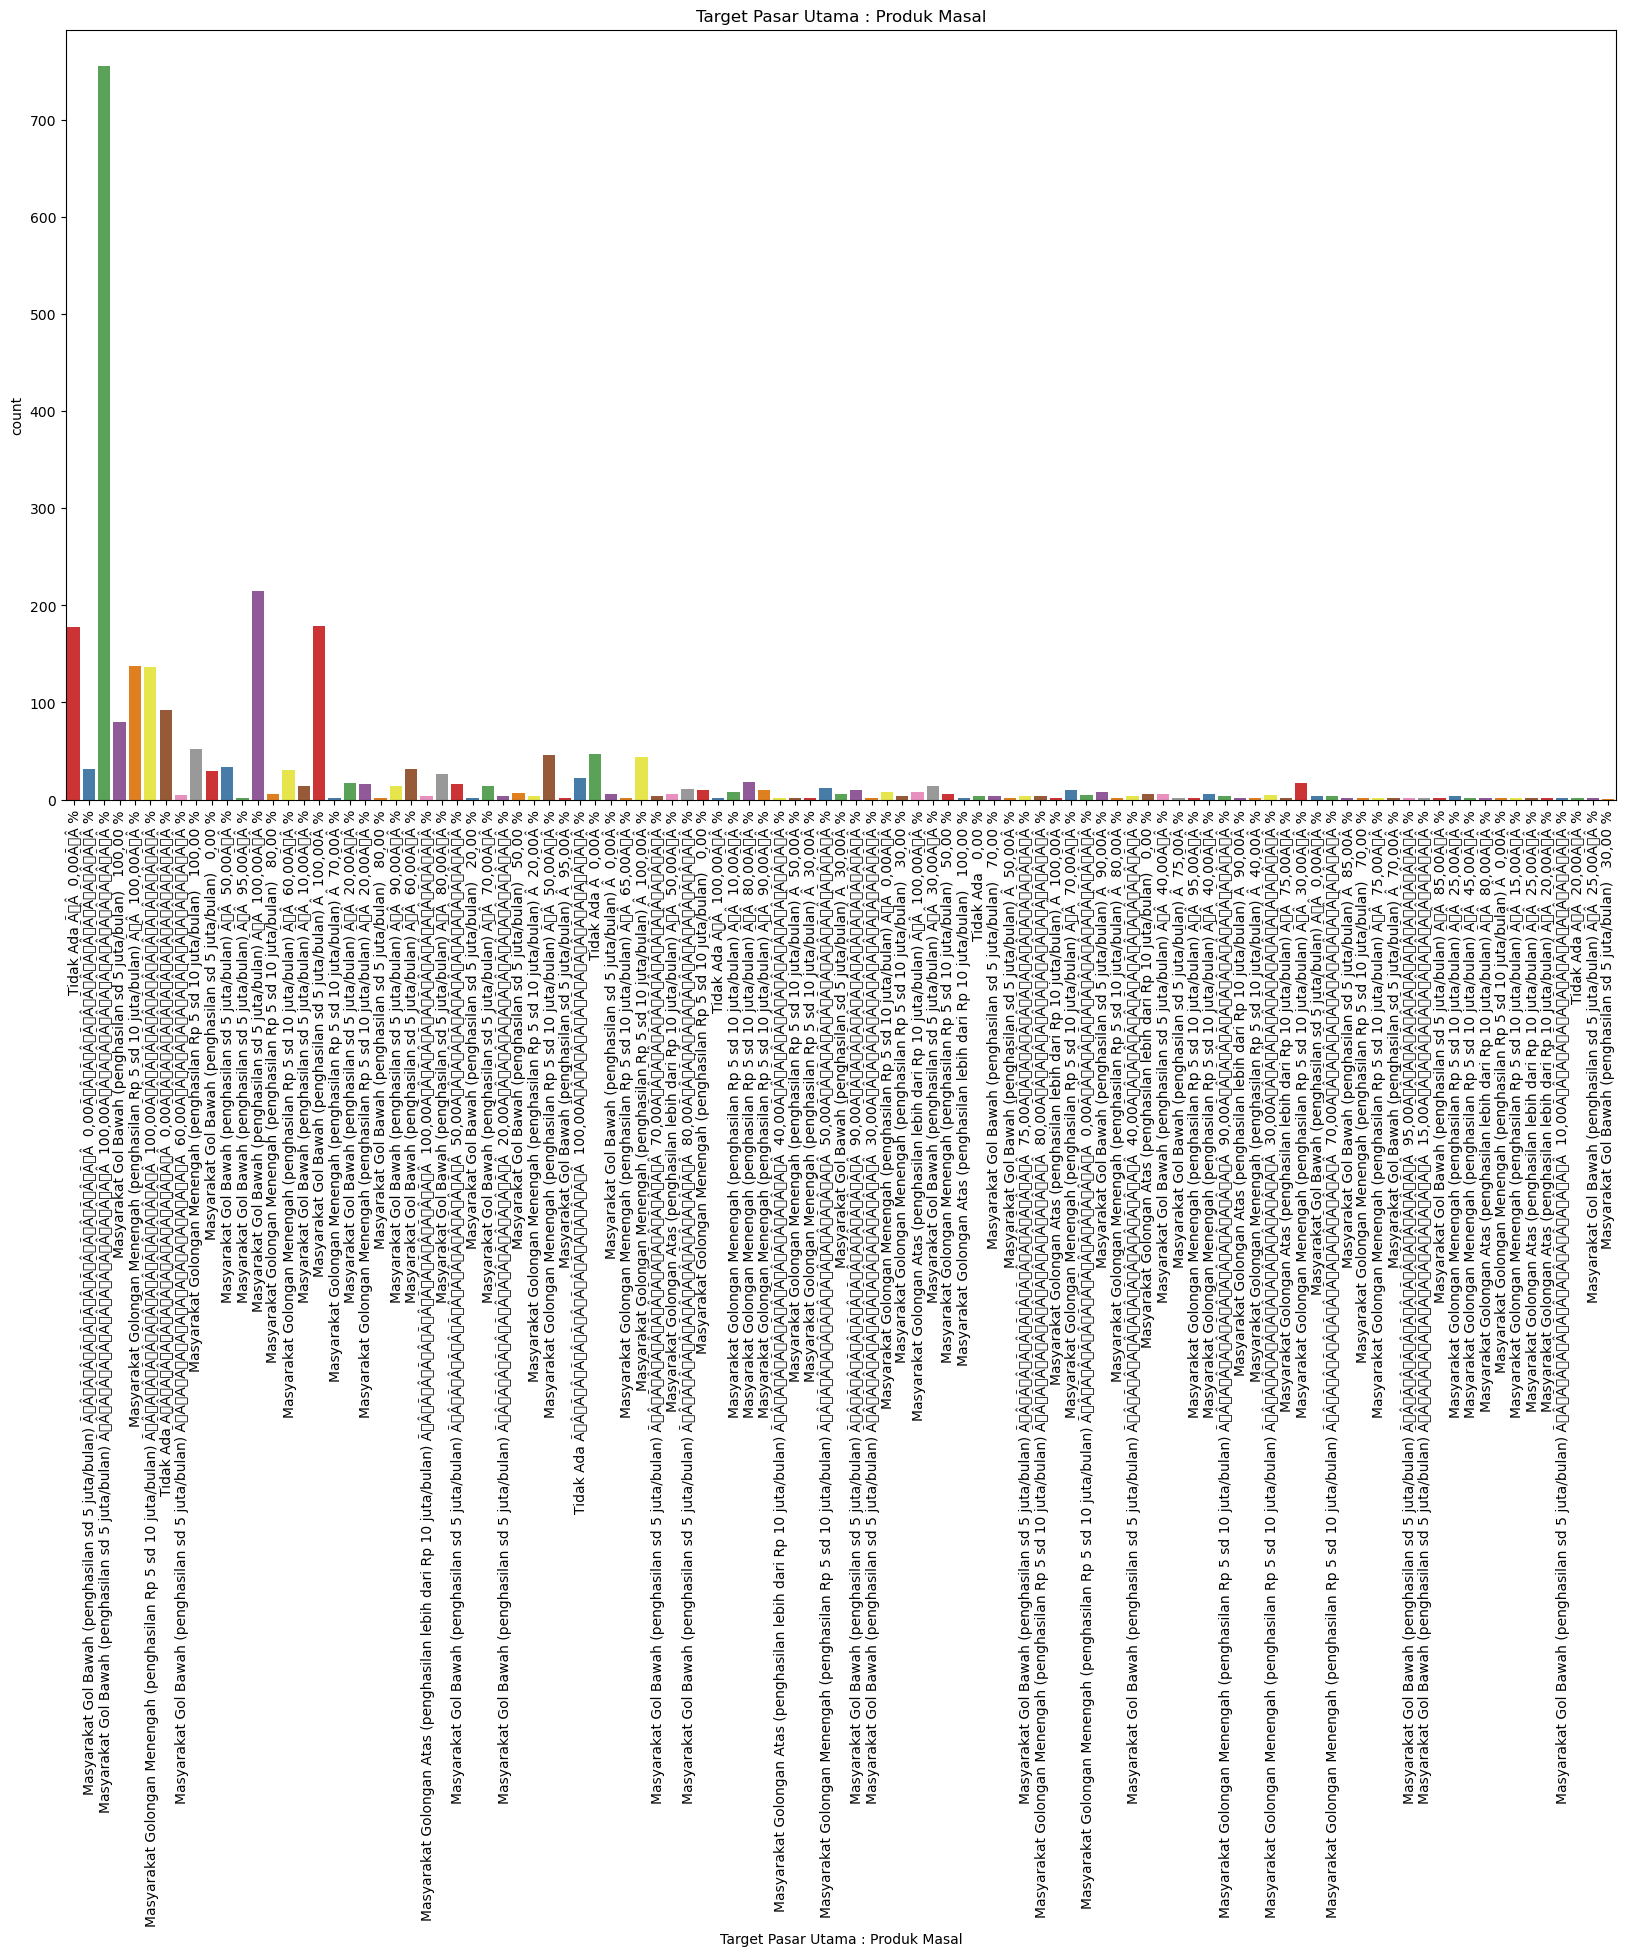

C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Glyph 130 (\x82) missing from current font.
  plt.tight_layout()
C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Glyph 131 (\x83) missing from current font.
  plt.tight_layout()
C:\Users\asus\AppData\Local\Temp\ipykernel_19140\580938031.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
c:\Users\asus\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 130 (\x82) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\asus\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 131 (\x83) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


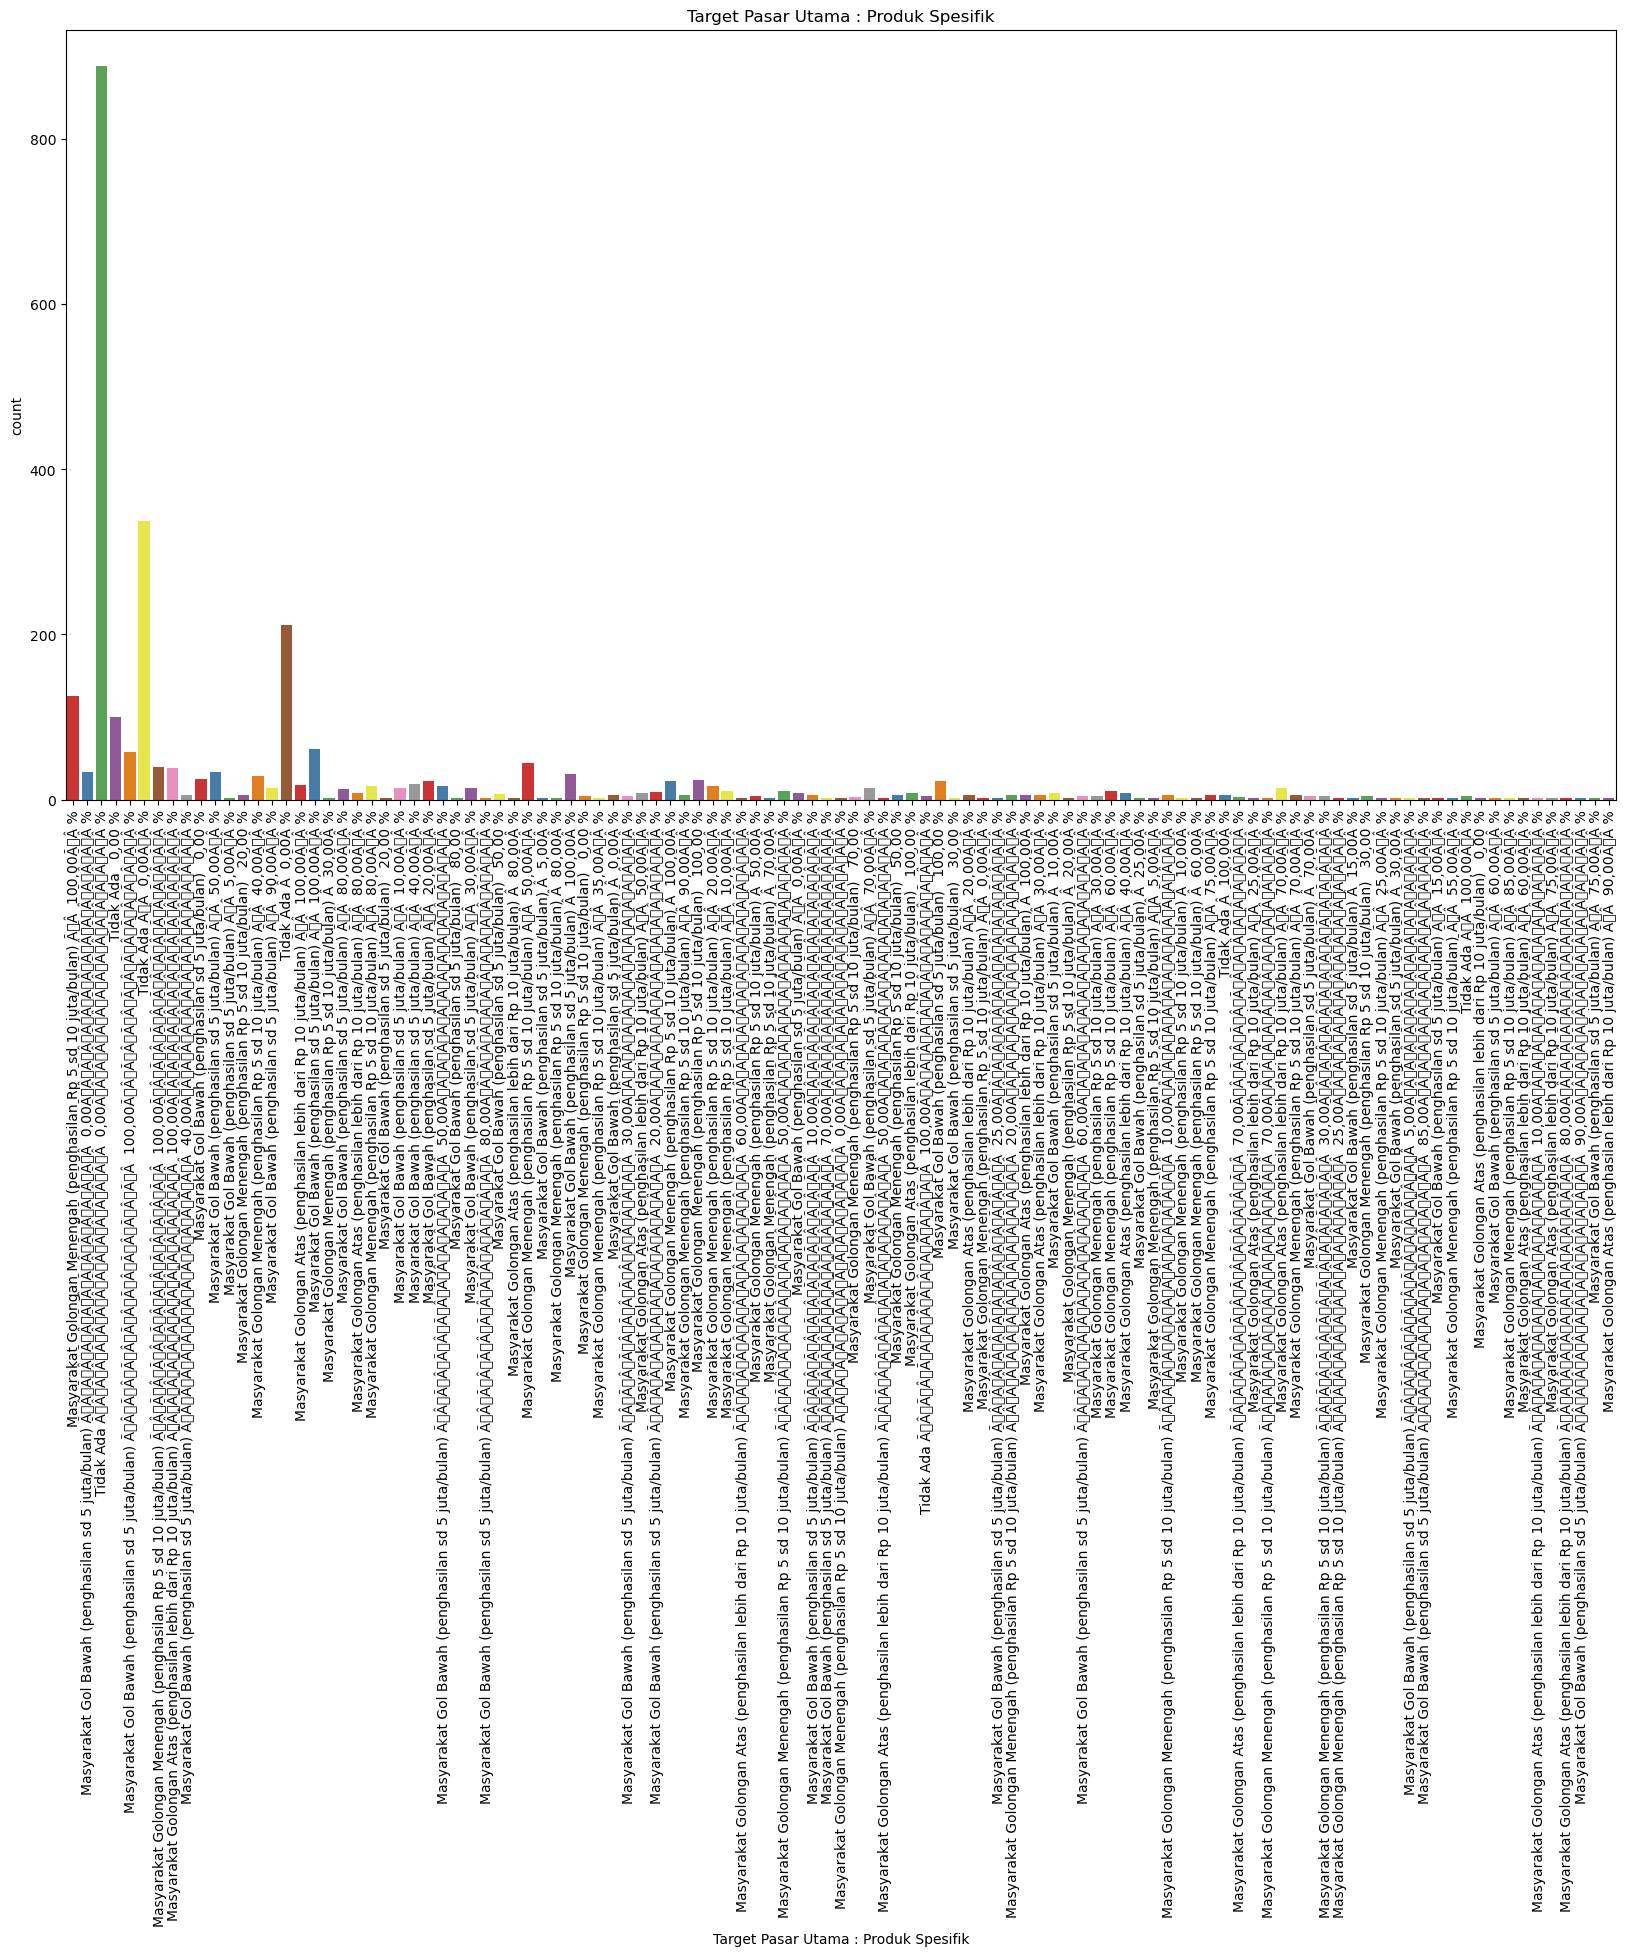

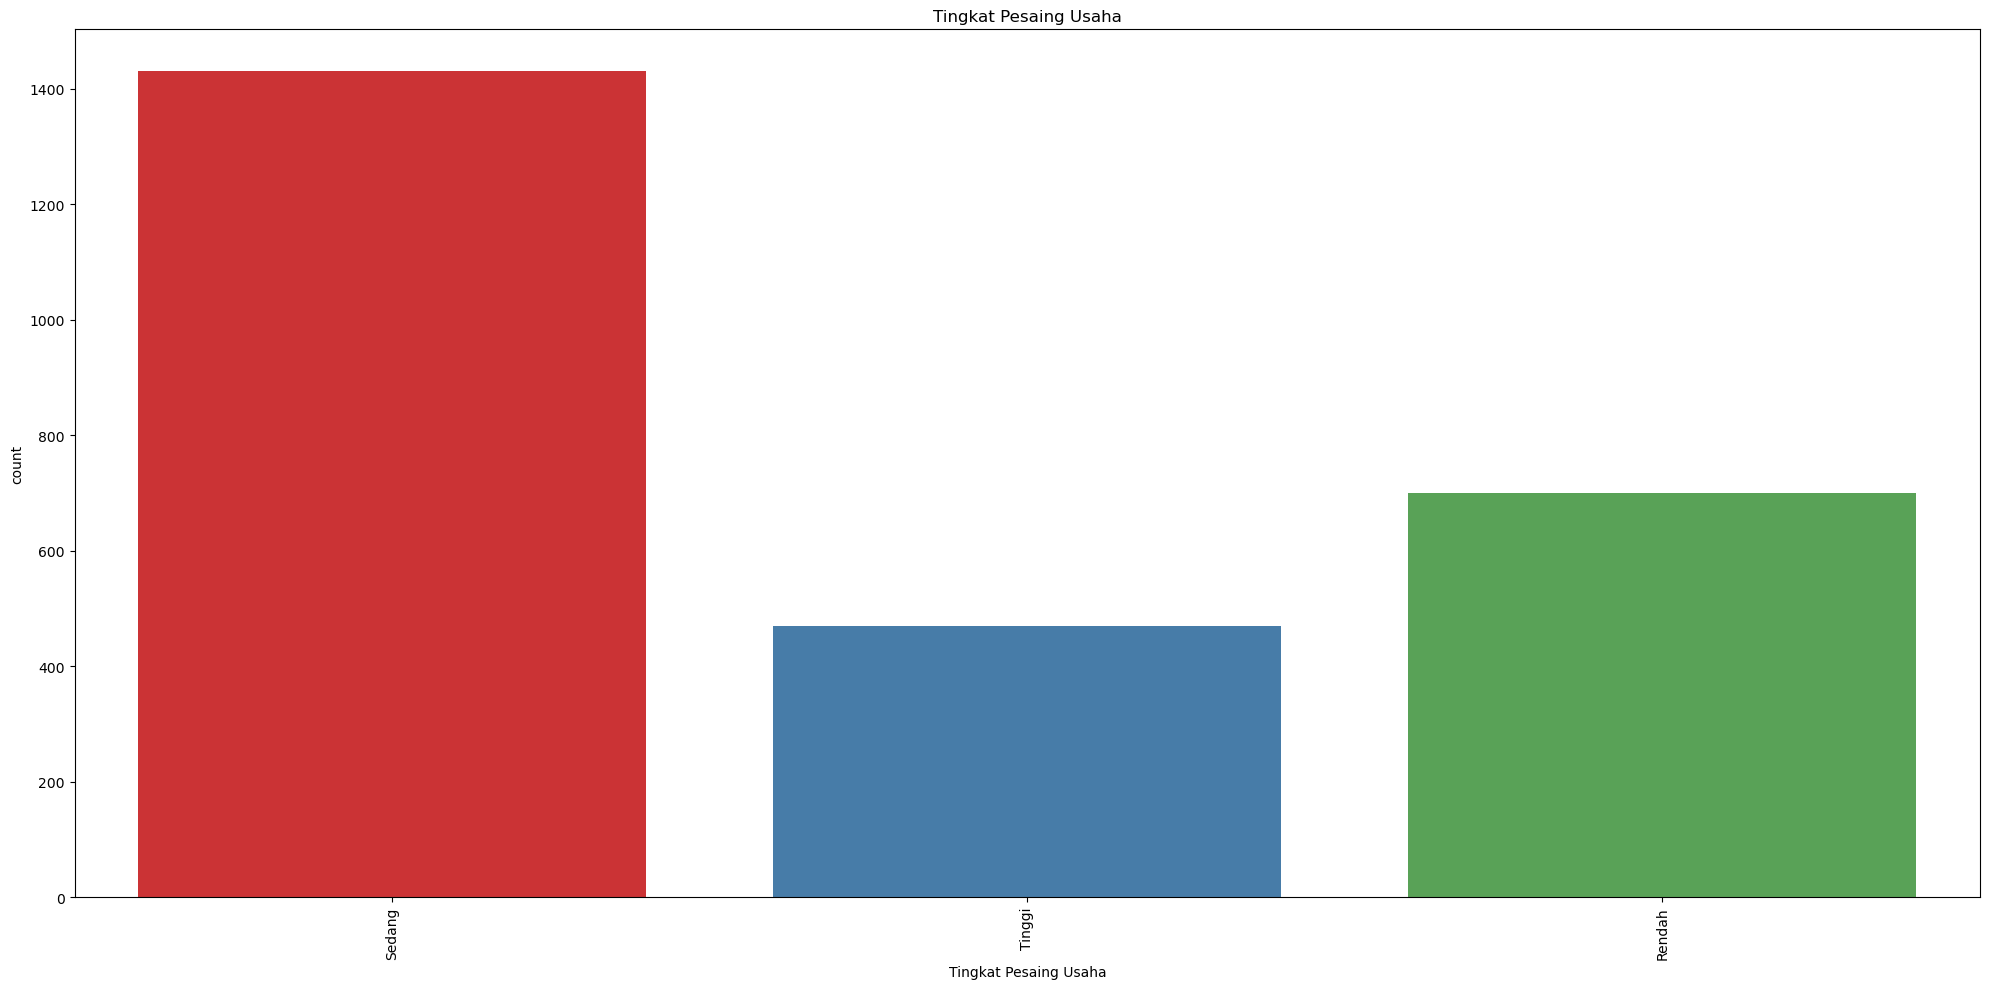

KeyboardInterrupt: 

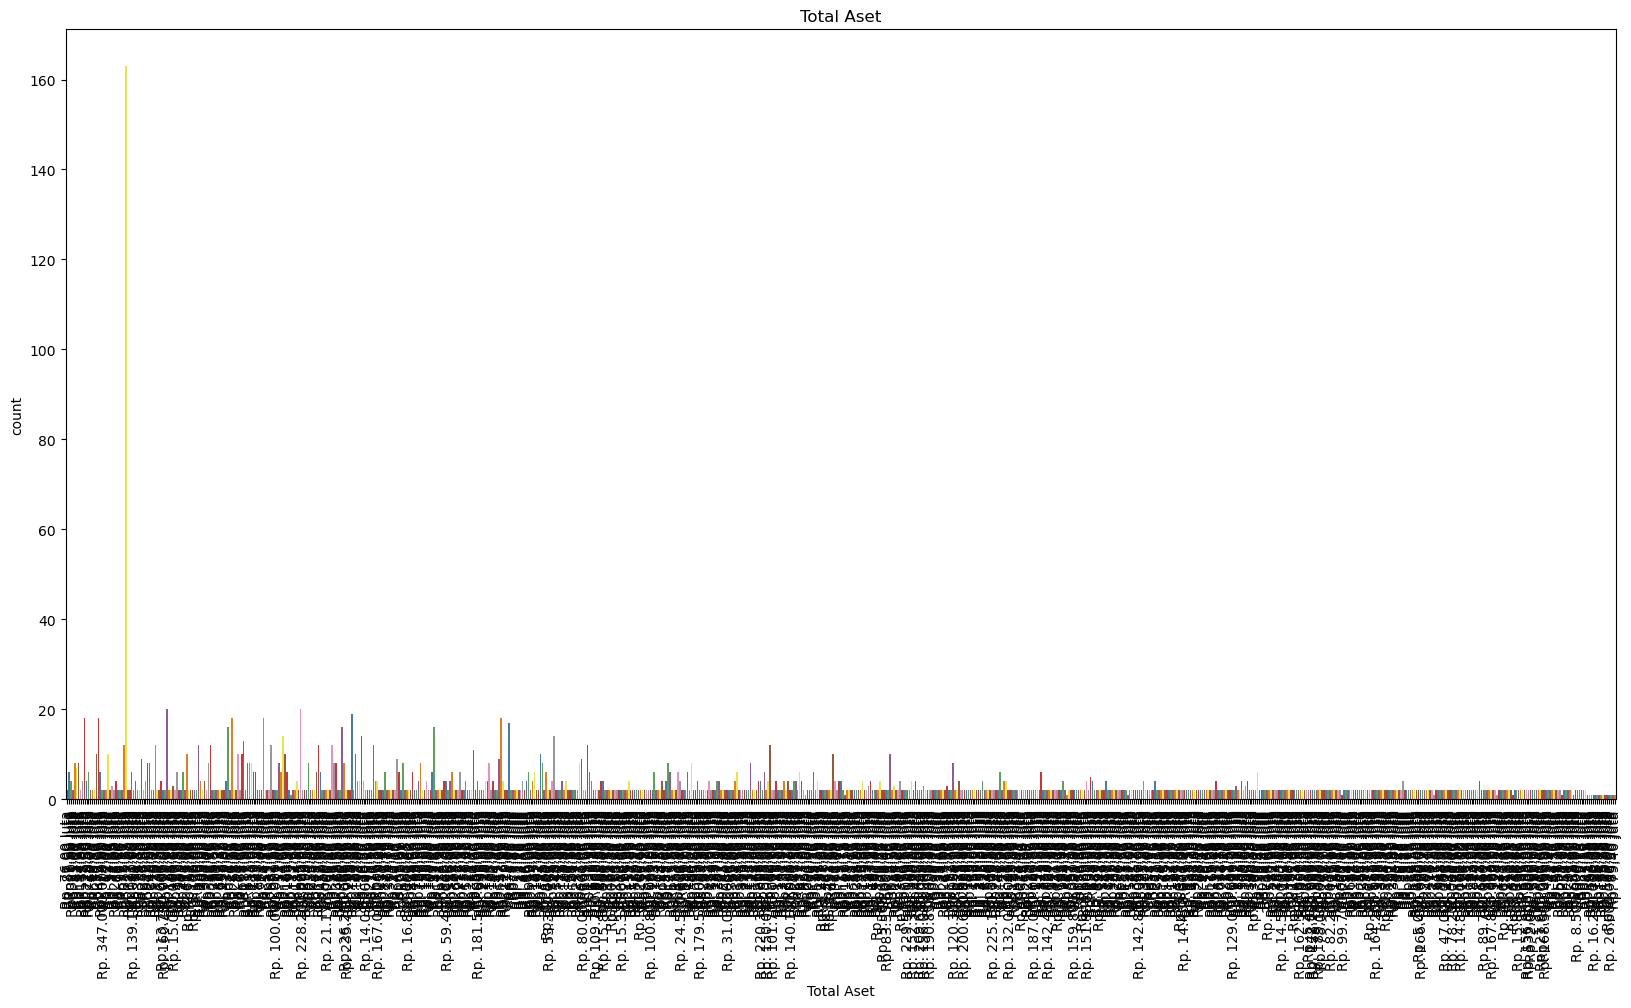

In [11]:
color_palette = sns.color_palette("Set1", len(cat_cols))
for i, column in enumerate(cat_cols, 1):
    if(column != 'Nama'):
        plt.figure(figsize=(20, 10))
        sns.countplot(data=df, x=column, palette=color_palette)
        plt.xticks(rotation=90)
        plt.title(column)
        plt.tight_layout()
        plt.show()

### Data Pre-Processing

In [ ]:
df.drop(columns=['Onclick','Jumlah Tenaga Kerja.1'],axis=1, inplace=True)

In [125]:
df.dropna(inplace=True)

In [126]:
df.isna().sum()

Usaha /Produk Utama                            0
Total Aset (Rp. Juta)                          0
Penjualan Rata-rata Per Tahun (Rp.Juta)        0
Jumlah Tenaga Kerja                            0
Tahun Survey                                   0
Sektor                                         0
Nama Badan Hukum                               0
Sistem Penjualan                               0
Target Pasar Utama : Produk Masal              0
Target Pasar Utama : Produk Spesifik           0
Tingkat Pesaing Usaha                          0
Total Aset                                     0
Penjualan Rata-Rata per Tahun                  0
Proyeksi Pertumbuhan Penjualan                 0
Kebutuhan Pembiayaan Kredit                    0
Nilai Aset yang data menjadi jaminan kredit    0
Jumlah Dokumen Persyaratan Kredit              0
Kelayakan                                      0
dtype: int64

In [127]:
import pandas as pd
import re

def nominalHandling(df: pd.DataFrame) -> pd.DataFrame:
    """
    Preprocess nominal values in Indonesian currency format to numeric values.
    
    Args:
        df (pd.DataFrame): Input DataFrame containing nominal columns
        
    Returns:
        pd.DataFrame: DataFrame with processed nominal values
    """
    # Create a copy to avoid modifying the original DataFrame
    df_processed = df.copy()
    
    # Columns to process
    nominal_columns = [
        'Total Aset',
        'Penjualan Rata-Rata per Tahun',
        'Kebutuhan Pembiayaan Kredit ',
        'Nilai Aset yang data menjadi jaminan kredit',
        'Total Aset (Rp. Juta)'
    ]
    
    def convert_currency_to_numeric(value):
        if pd.isna(value) or not isinstance(value, str):
            return value
            
        # Remove 'Rp.', spaces, and any other currency symbols
        value = str(value).replace('Rp.', '').replace('Rp', '').strip()
        
        # Handle numbers with dots as thousand separators (e.g., 347.000.000.00)
        if re.match(r'^[\d.]+$', value):
            # Remove all dots except the last one (which might be decimal)
            parts = value.rsplit('.', 1)
            if len(parts) > 1:
                integer_part = parts[0].replace('.', '')
                decimal_part = parts[1]
                value = f"{integer_part}.{decimal_part}"
            else:
                value = value.replace('.', '')
            return float(value)
        
        # Extract the numeric part and the unit (Juta/Milyar)
        match = re.match(r'([0-9.,]+)\s*(Juta|Milyar)?', value)
        if not match:
            return value
            
        number, unit = match.groups()
        
        # Convert number string to float (handling Indonesian format)
        number = number.replace('.', '').replace(',', '.')
        number = float(number)
        

        if unit == 'Juta':
            number *= 1
        elif unit == 'Milyar':
            number *= 10
        return number
    
    # Apply conversion to specified columns
    for column in nominal_columns:
        if column in df_processed.columns:
            df_processed[column] = df_processed[column].apply(convert_currency_to_numeric)
            df_processed[column].astype(float)
    df_processed['Total Aset (Rp. Juta)'] = df_processed['Total Aset (Rp. Juta)']*1
    return df_processed

In [128]:
df_nominal_pre_processed = nominalHandling(df)

In [129]:
df_nominal_pre_processed

,Usaha /Produk Utama,Total Aset (Rp. Juta),Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Total Aset,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan
0,Pembuatan Gorden,76.000,340,7.0,2008.0,Industri Pengolahan,Perorangan,Retail,"Tidak Ada ÃÂ 0,00ÃÂ %",Masyarakat Golongan Menengah (penghasilan Rp 5...,Sedang,76.0,340.0,15 %/Tahun,0.0,250.0,10.0,yes
1,Warung,87.000,384,1.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,87.0,384.0,20 %/Tahun,10.0,33.0,6.0,no
2,Dagang Ikan,1.500,201,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,1.5,201.0,20 %/Tahun,10.0,287.0,6.0,no
3,Toko,320.000,180,2.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Tinggi,320.0,180.0,10 %/Tahun,10.0,7.0,4.0,no
4,Petani Padi,33.000,20,1.0,2012.0,"Pertanian, Kehutanan, dan Perikanan",Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada 0,00 %",Rendah,33.0,20.0,20 %/Tahun,2.0,36.0,3.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,Dagang Topi Dan Aksesoris Sekolah,25.600,58,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Rendah,25.6,58.0,10 %/Tahun,6.0,119.0,5.0,no
2640,Toko Serba Ada,1.597,4.950,14.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,1597.0,4950.0,30 %/Tahun,0.0,250.0,11.0,no
2641,Pembuatan Sapu Ijuk Dan Pel,26600.000,324,1.0,2011.0,Industri Pengolahan,Perorangan,Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂ 0,00ÃÂ %",Tinggi,26600000.0,324.0,25 %/Tahun,9.0,14.0,5.0,no
2642,Dagang Sembako,89.500,74,2.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,89.5,74.0,5 %/Tahun,0.0,80.0,4.0,no


In [131]:
import pandas as pd
import numpy as np

def analyzeAssetColumns(df: pd.DataFrame, 
                       col1: str = 'Total Aset', 
                       col2: str = 'Total Aset (Rp. Juta)') -> dict:
    """
    Analyze differences between two asset columns and provide statistical insights.
    
    Args:
        df (pd.DataFrame): Input DataFrame containing the asset columns
        col1 (str): Name of first asset column (default: 'Total Aset')
        col2 (str): Name of second asset column in millions (default: 'Total Aset (Rp. Juta)')
        
    Returns:
        dict: Dictionary containing analysis results
    """
    # Create a copy and ensure col2 is in the same scale as col1
    df_analysis = df.copy()
    df_analysis[f'{col2}_adjusted'] = df_analysis[col2] * 1_000_000
    
    # Calculate differences and ratios
    df_analysis['difference'] = df_analysis[col1] - df_analysis[f'{col2}_adjusted']
    df_analysis['ratio'] = df_analysis[col1] / df_analysis[f'{col2}_adjusted']
    
    # Find significant discrepancies
    significant_diff = df_analysis[abs(df_analysis['ratio']) > 100]
    
    # Prepare analysis results
    analysis = {
        'total_rows': len(df_analysis),
        'matching_values': len(df_analysis[df_analysis['difference'] == 0]),
        'significant_differences': len(significant_diff),
        'max_difference': df_analysis['difference'].abs().max(),
        'mean_difference': df_analysis['difference'].mean(),
        'median_difference': df_analysis['difference'].median(),
        'std_difference': df_analysis['difference'].std(),
        'problematic_rows': significant_diff.index.tolist()
    }
    
    # Calculate correlation
    analysis['correlation'] = df_analysis[[col1, f'{col2}_adjusted']].corr().iloc[0,1]
    
    # Generate summary text
    analysis['summary'] = f"""
    Analysis Summary:
    - Total rows analyzed: {analysis['total_rows']}
    - Exactly matching values: {analysis['matching_values']} ({(analysis['matching_values']/analysis['total_rows']*100):.1f}%)
    - Significant discrepancies: {analysis['significant_differences']}
    - Maximum absolute difference: {analysis['max_difference']:,.2f}
    - Correlation coefficient: {analysis['correlation']:.3f}
    """
    
    return analysis

In [132]:
results = analyzeAssetColumns(df_nominal_pre_processed)
print(results['summary'])


    Analysis Summary:
    - Total rows analyzed: 2448
    - Exactly matching values: 0 (0.0%)
    - Significant discrepancies: 0
    - Maximum absolute difference: 534,465,000,000.00
    - Correlation coefficient: 1.000
    


Total Aset
Skew : 6.87


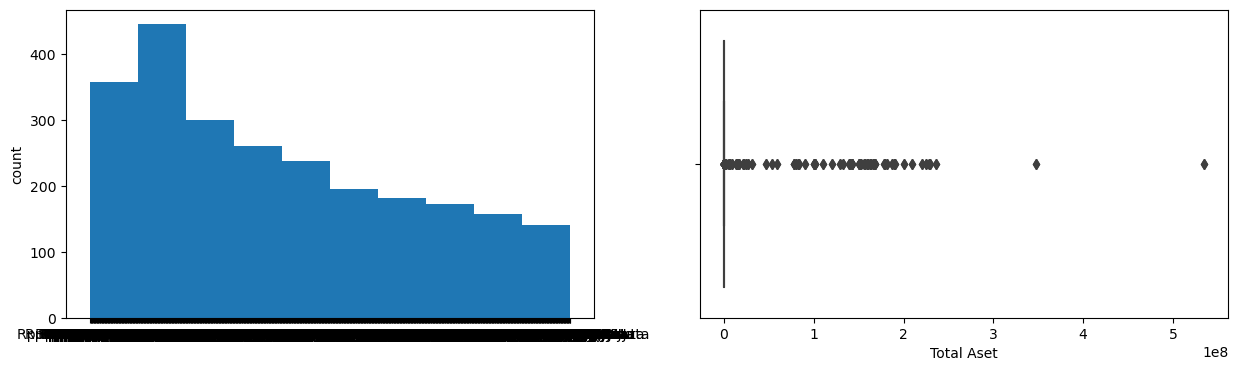

Total Aset (Rp. Juta)
Skew : 6.88


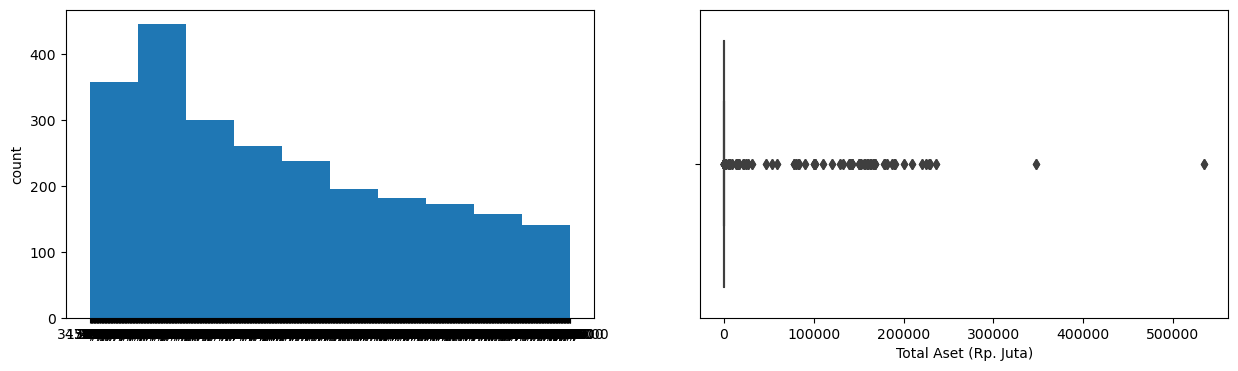

In [133]:
for col in ['Total Aset', 'Total Aset (Rp. Juta)']:
    print(col)
    print('Skew :', round(df_nominal_pre_processed[col].skew(), 2))
    plt.figure(figsize = (15, 4))
    plt.subplot(1, 2, 1)
    df[col].hist(grid=False)
    plt.ylabel('count')
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df_nominal_pre_processed[col])
    plt.show()

In [134]:
df_nominal_pre_processed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2448 entries, 0 to 2643
Data columns (total 18 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Usaha /Produk Utama                          2448 non-null   object 
 1   Total Aset (Rp. Juta)                        2448 non-null   float64
 2   Penjualan Rata-rata Per Tahun (Rp.Juta)      2448 non-null   object 
 3   Jumlah Tenaga Kerja                          2448 non-null   float64
 4   Tahun Survey                                 2448 non-null   float64
 5   Sektor                                       2448 non-null   object 
 6   Nama Badan Hukum                             2448 non-null   object 
 7   Sistem Penjualan                             2448 non-null   object 
 8   Target Pasar Utama : Produk Masal            2448 non-null   object 
 9   Target Pasar Utama : Produk Spesifik         2448 non-null   object 
 10  Tingk

In [172]:
import pandas as pd
import numpy as np

def consolidateAssetColumns(df: pd.DataFrame, 
                          col1: str = 'Total Aset', 
                          col2: str = 'Total Aset (Rp. Juta)',
                          ratio_threshold: float = 100,
                          output_col: str = 'Total Aset Final') -> pd.DataFrame:
    """
    Consolidate two asset columns into a single column by comparing their values
    and selecting the appropriate one based on magnitude difference.
    
    Args:
        df (pd.DataFrame): Input DataFrame containing the asset columns
        col1 (str): Name of first asset column (default: 'Total Aset')
        col2 (str): Name of second asset column in millions (default: 'Total Aset (Rp. Juta)')
        ratio_threshold (float): Threshold for ratio difference to trigger using minimum value (default: 100)
        output_col (str): Name of the output consolidated column (default: 'Total Aset Final')
        
    Returns:
        pd.DataFrame: DataFrame with new consolidated asset column
    """
    # Create a copy to avoid modifying the original DataFrame
    df_processed = df.copy()
    
    # Check if both columns exist
    if not all(col in df_processed.columns for col in [col1, col2]):
        raise ValueError(f"One or both columns {col1} and {col2} not found in DataFrame")
    
    def resolve_asset_values(row):
        """
        Helper function to resolve values between two asset columns
        """
        # Get values from both columns
        value1 = row[col1] if pd.notna(row[col1]) else 0
        value2 = row[col2] * 1_000_000 if pd.notna(row[col2]) else 0  # Convert millions to absolute value
        
        # Handle cases where one value is missing/zero
        if value1 == 0:
            return value2
        if value2 == 0:
            return value1
            
        # Calculate ratio between values
        ratio = max(value1, value2) / min(value1, value2)
        
        # If ratio exceeds threshold, use minimum value
        if ratio > ratio_threshold:
            return min(value1, value2)
        # Otherwise use maximum value
        return max(value1, value2)
    
    # Create new consolidated column
    df_processed[output_col] = df_processed.apply(resolve_asset_values, axis=1)
    
    return df_processed.drop(axis=1, columns=["Total Aset (Rp. Juta)","Total Aset"])

In [173]:
df_asset_pre_processed = consolidateAssetColumns(df_nominal_pre_processed)

In [175]:
df_asset_pre_processed

,Usaha /Produk Utama,Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan,Total Aset Final
0,Pembuatan Gorden,340,7.0,2008.0,Industri Pengolahan,Perorangan,Retail,"Tidak Ada ÃÂ 0,00ÃÂ %",Masyarakat Golongan Menengah (penghasilan Rp 5...,Sedang,340.0,15 %/Tahun,0.0,250.0,10.0,yes,76.0
1,Warung,384,1.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,384.0,20 %/Tahun,10.0,33.0,6.0,no,87.0
2,Dagang Ikan,201,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,201.0,20 %/Tahun,10.0,287.0,6.0,no,1.5
3,Toko,180,2.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Tinggi,180.0,10 %/Tahun,10.0,7.0,4.0,no,320.0
4,Petani Padi,20,1.0,2012.0,"Pertanian, Kehutanan, dan Perikanan",Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada 0,00 %",Rendah,20.0,20 %/Tahun,2.0,36.0,3.0,no,33.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,Dagang Topi Dan Aksesoris Sekolah,58,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Rendah,58.0,10 %/Tahun,6.0,119.0,5.0,no,25.6
2640,Toko Serba Ada,4.950,14.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,4950.0,30 %/Tahun,0.0,250.0,11.0,no,1597.0
2641,Pembuatan Sapu Ijuk Dan Pel,324,1.0,2011.0,Industri Pengolahan,Perorangan,Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂ 0,00ÃÂ %",Tinggi,324.0,25 %/Tahun,9.0,14.0,5.0,no,26600000.0
2642,Dagang Sembako,74,2.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,74.0,5 %/Tahun,0.0,80.0,4.0,no,89.5


In [176]:
df_asset_pre_processed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2448 entries, 0 to 2643
Data columns (total 17 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Usaha /Produk Utama                          2448 non-null   object 
 1   Penjualan Rata-rata Per Tahun (Rp.Juta)      2448 non-null   object 
 2   Jumlah Tenaga Kerja                          2448 non-null   float64
 3   Tahun Survey                                 2448 non-null   float64
 4   Sektor                                       2448 non-null   object 
 5   Nama Badan Hukum                             2448 non-null   object 
 6   Sistem Penjualan                             2448 non-null   object 
 7   Target Pasar Utama : Produk Masal            2448 non-null   object 
 8   Target Pasar Utama : Produk Spesifik         2448 non-null   object 
 9   Tingkat Pesaing Usaha                        2448 non-null   object 
 10  Penju

In [177]:
import pandas as pd
import re

def preprocessGrowthProjection(df: pd.DataFrame, 
                             column: str = 'Proyeksi Pertumbuhan Penjualan') -> pd.DataFrame:
    """
    Preprocess growth projection values by converting percentage strings to decimal numbers.
    
    Args:
        df (pd.DataFrame): Input DataFrame containing the growth projection column
        column (str): Name of the column to process (default: 'Proyeksi Pertumbuhan Penjualan')
        
    Returns:
        pd.DataFrame: DataFrame with processed growth projection values
    """
    def convert_growth_to_decimal(value):
        if pd.isna(value):
            return value
            
        # Convert to string to handle any numeric inputs
        value = str(value).strip()
        
        # Try to extract numeric value using regex
        # This will match patterns like "15 %/Tahun", "15%", "15 persen", etc.
        match = re.search(r'([-+]?\d*\.?\d+)', value)
        
        if match:
            # Extract the numeric value
            number = float(match.group(1))
            
            # Convert percentage to decimal
            return number / 100
        
        return None
    
    # Create a copy to avoid modifying the original DataFrame
    df_processed = df.copy()
    
    # Check if column exists
    if column not in df_processed.columns:
        raise ValueError(f"Column '{column}' not found in DataFrame")
    
    # Apply conversion
    df_processed[column] = df_processed[column].apply(convert_growth_to_decimal)
    
    return df_processed

In [178]:
df_growthprojection_preprocessed = preprocessGrowthProjection(df_asset_pre_processed)

In [179]:
df_growthprojection_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2448 entries, 0 to 2643
Data columns (total 17 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Usaha /Produk Utama                          2448 non-null   object 
 1   Penjualan Rata-rata Per Tahun (Rp.Juta)      2448 non-null   object 
 2   Jumlah Tenaga Kerja                          2448 non-null   float64
 3   Tahun Survey                                 2448 non-null   float64
 4   Sektor                                       2448 non-null   object 
 5   Nama Badan Hukum                             2448 non-null   object 
 6   Sistem Penjualan                             2448 non-null   object 
 7   Target Pasar Utama : Produk Masal            2448 non-null   object 
 8   Target Pasar Utama : Produk Spesifik         2448 non-null   object 
 9   Tingkat Pesaing Usaha                        2448 non-null   object 
 10  Penju

In [180]:
df_growthprojection_preprocessed

,Usaha /Produk Utama,Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan,Total Aset Final
0,Pembuatan Gorden,340,7.0,2008.0,Industri Pengolahan,Perorangan,Retail,"Tidak Ada ÃÂ 0,00ÃÂ %",Masyarakat Golongan Menengah (penghasilan Rp 5...,Sedang,340.0,0.15,0.0,250.0,10.0,yes,76.0
1,Warung,384,1.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,384.0,0.20,10.0,33.0,6.0,no,87.0
2,Dagang Ikan,201,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,201.0,0.20,10.0,287.0,6.0,no,1.5
3,Toko,180,2.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Tinggi,180.0,0.10,10.0,7.0,4.0,no,320.0
4,Petani Padi,20,1.0,2012.0,"Pertanian, Kehutanan, dan Perikanan",Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada 0,00 %",Rendah,20.0,0.20,2.0,36.0,3.0,no,33.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,Dagang Topi Dan Aksesoris Sekolah,58,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Rendah,58.0,0.10,6.0,119.0,5.0,no,25.6
2640,Toko Serba Ada,4.950,14.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ 0,0...",Sedang,4950.0,0.30,0.0,250.0,11.0,no,1597.0
2641,Pembuatan Sapu Ijuk Dan Pel,324,1.0,2011.0,Industri Pengolahan,Perorangan,Distributor,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,"Tidak Ada ÃÂ 0,00ÃÂ %",Tinggi,324.0,0.25,9.0,14.0,5.0,no,26600000.0
2642,Dagang Sembako,74,2.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Masyarakat Gol Bawah (penghasilan sd 5 juta/bu...,Sedang,74.0,0.05,0.0,80.0,4.0,no,89.5


In [181]:
def targetPasarPreprocessing(df):
    def simplify_golongan(value):
        if 'Gol Bawah' in str(value):
            return "Gol Bawah"
        elif  "Menengah" in str(value):
            return "Menengah"
        elif "Atas" in str(value):
            return "Atas"

        elif "Tidak" in str(value):
            return "Tidak ada"

        return value
    df['Target Pasar Utama : Produk Spesifik'] = df['Target Pasar Utama : Produk Spesifik'].apply(simplify_golongan)
    df['Target Pasar Utama : Produk Masal'] = df['Target Pasar Utama : Produk Masal'].apply(simplify_golongan)
    return df

In [182]:
df_target_pasar_preprocessed = targetPasarPreprocessing(df_growthprojection_preprocessed)


In [183]:
df_target_pasar_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2448 entries, 0 to 2643
Data columns (total 17 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Usaha /Produk Utama                          2448 non-null   object 
 1   Penjualan Rata-rata Per Tahun (Rp.Juta)      2448 non-null   object 
 2   Jumlah Tenaga Kerja                          2448 non-null   float64
 3   Tahun Survey                                 2448 non-null   float64
 4   Sektor                                       2448 non-null   object 
 5   Nama Badan Hukum                             2448 non-null   object 
 6   Sistem Penjualan                             2448 non-null   object 
 7   Target Pasar Utama : Produk Masal            2448 non-null   object 
 8   Target Pasar Utama : Produk Spesifik         2448 non-null   object 
 9   Tingkat Pesaing Usaha                        2448 non-null   object 
 10  Penju

In [184]:
df_target_pasar_preprocessed

,Usaha /Produk Utama,Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan,Total Aset Final
0,Pembuatan Gorden,340,7.0,2008.0,Industri Pengolahan,Perorangan,Retail,Tidak ada,Menengah,Sedang,340.0,0.15,0.0,250.0,10.0,yes,76.0
1,Warung,384,1.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Gol Bawah,Gol Bawah,Sedang,384.0,0.20,10.0,33.0,6.0,no,87.0
2,Dagang Ikan,201,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Gol Bawah,Tidak ada,Sedang,201.0,0.20,10.0,287.0,6.0,no,1.5
3,Toko,180,2.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Gol Bawah,Tidak ada,Tinggi,180.0,0.10,10.0,7.0,4.0,no,320.0
4,Petani Padi,20,1.0,2012.0,"Pertanian, Kehutanan, dan Perikanan",Perorangan,Retail,Gol Bawah,Tidak ada,Rendah,20.0,0.20,2.0,36.0,3.0,no,33.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,Dagang Topi Dan Aksesoris Sekolah,58,1.0,2010.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Gol Bawah,Tidak ada,Rendah,58.0,0.10,6.0,119.0,5.0,no,25.6
2640,Toko Serba Ada,4.950,14.0,2013.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail dan Distributor,Gol Bawah,Tidak ada,Sedang,4950.0,0.30,0.0,250.0,11.0,no,1597.0
2641,Pembuatan Sapu Ijuk Dan Pel,324,1.0,2011.0,Industri Pengolahan,Perorangan,Distributor,Gol Bawah,Tidak ada,Tinggi,324.0,0.25,9.0,14.0,5.0,no,26600000.0
2642,Dagang Sembako,74,2.0,2011.0,Perdagangan Besar dan Eceran Reparasi dan Pera...,Perorangan,Retail,Gol Bawah,Gol Bawah,Sedang,74.0,0.05,0.0,80.0,4.0,no,89.5


In [185]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

def encodingPreProcessing(df: pd.DataFrame) -> pd.DataFrame:
    """
    Preprocess categorical columns using ordinal encoding for specified columns
    and label encoding for remaining categorical columns.
    
    Args:
        df (pd.DataFrame): Input DataFrame
        
    Returns:
        pd.DataFrame: DataFrame with encoded categorical columns
    """
    # Create a copy to avoid modifying the original DataFrame
    df_processed = df.copy()
    
    # Define ordinal encoding mappings
    ordinalEncoding = {
        "Target Pasar Utama : Produk Masal": {
            "Tidak ada": 0,
            "Gol Bawah": 1,
            "Menengah": 2,
            "Atas": 3
        },
        "Target Pasar Utama : Produk Spesifik": {
            "Tidak ada": 0,
            "Gol Bawah": 1,
            "Menengah": 2,
            "Atas": 3
        },
        "Tingkat Pesaing Usaha": {
            "Rendah": 0,
            "Sedang": 1,
            "Tinggi": 2
        }
    }
    
    # Apply ordinal encoding for specified columns
    for column, mapping in ordinalEncoding.items():
        if column in df_processed.columns:
            df_processed[column] = df_processed[column].map(mapping)
            # Handle any missing mappings
            if df_processed[column].isna().any():
                print(f"Warning: Found unmapped categories in column '{column}': "
                      f"{df_processed[df_processed[column].isna()][column].unique()}")
    
    # Find remaining categorical columns
    # Exclude columns that were ordinal encoded and numeric columns
    categorical_columns = df_processed.select_dtypes(include=['object']).columns
    categorical_columns = [col for col in categorical_columns 
                         if col not in ordinalEncoding.keys()]
    
    # Apply label encoding to remaining categorical columns
    label_encoders = {}
    for column in categorical_columns:
        le = LabelEncoder()
        # Handle NaN values if present
        non_null_mask = df_processed[column].notna()
        if non_null_mask.all():
            # No NaN values
            df_processed[column] = le.fit_transform(df_processed[column])
        else:
            # Handle NaN values
            non_null_values = df_processed[column][non_null_mask]
            if len(non_null_values) > 0:
                df_processed.loc[non_null_mask, column] = le.fit_transform(non_null_values)
            
        # Store the encoder for future reference
        label_encoders[column] = le
        
        # Print unique value mappings for reference
        if len(le.classes_) < 10:  # Only print if there aren't too many categories
            mapping = dict(zip(le.classes_, le.transform(le.classes_)))
            print(f"\nLabel encoding mapping for {column}:")
            print(mapping)
    
    # Store encoders as attribute for future reference
    df_processed.attrs['label_encoders'] = label_encoders
    df_processed.attrs['ordinal_encoding'] = ordinalEncoding
    
    return df_processed

In [186]:
df_encoded_preprocessed = encodingPreProcessing(df_target_pasar_preprocessed)


Label encoding mapping for Nama Badan Hukum:
{'CV': 0, 'Koperasi': 1, 'Perorangan': 2, 'Usaha Dagang (UD)': 3}

Label encoding mapping for Sistem Penjualan:
{'-': 0, 'Distributor': 1, 'Retail': 2, 'Retail dan Distributor': 3}

Label encoding mapping for Kelayakan:
{'no': 0, 'yes': 1}


In [187]:
df_encoded_preprocessed 

,Usaha /Produk Utama,Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan,Total Aset Final
0,461,275,7.0,2008.0,0,2,2,0,2,1,340.0,0.15,0.0,250.0,10.0,1,76.0
1,770,304,1.0,2011.0,9,2,2,1,1,1,384.0,0.20,10.0,33.0,6.0,0,87.0
2,111,156,1.0,2010.0,9,2,2,1,0,1,201.0,0.20,10.0,287.0,6.0,0,1.5
3,738,125,2.0,2013.0,9,2,2,1,0,2,180.0,0.10,10.0,7.0,4.0,0,320.0
4,646,149,1.0,2012.0,11,2,2,1,0,0,20.0,0.20,2.0,36.0,3.0,0,33.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,185,397,1.0,2010.0,9,2,3,1,0,0,58.0,0.10,6.0,119.0,5.0,0,25.6
2640,752,315,14.0,2013.0,9,2,3,1,0,1,4950.0,0.30,0.0,250.0,11.0,0,1597.0
2641,547,260,1.0,2011.0,0,2,1,1,0,2,324.0,0.25,9.0,14.0,5.0,0,26600000.0
2642,169,441,2.0,2011.0,9,2,2,1,1,1,74.0,0.05,0.0,80.0,4.0,0,89.5


In [272]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

def minMaxScalingPreprocessing(df: pd.DataFrame, 
                      exclude_columns: list = None,
                      include_columns: list = None) -> pd.DataFrame:
    """
    Apply MinMax scaling to numerical columns in the DataFrame.
    
    Args:
        df (pd.DataFrame): Input DataFrame
        exclude_columns (list, optional): List of numerical columns to exclude from scaling
        include_columns (list, optional): List of specific columns to scale (if None, scales all numeric columns)
        
    Returns:
        pd.DataFrame: DataFrame with scaled numerical columns
        dict: Dictionary containing the fitted scalers
    """
    # Create a copy to avoid modifying the original DataFrame
    df_scaled = df.copy()
    
    # Initialize dictionary to store scalers
    scalers = {}
    
    # Get numerical columns
    numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
    
    # Determine which columns to scale
    if include_columns is not None:
        columns_to_scale = [col for col in include_columns if col in numeric_columns]
    else:
        columns_to_scale = numeric_columns

    # Remove excluded columns
    if exclude_columns:
        columns_to_scale = [col for col in columns_to_scale if col not in exclude_columns]
    
    # Apply scaling to each numeric column
    for column in columns_to_scale:
        if(column != "id" and column != "Kelayakan"):
            # Create a scaler for this column
            scaler = MinMaxScaler()
            
            # Reshape data for scaling
            data = df_scaled[column].values.reshape(-1, 1)
            
            # Handle missing values if present
            if np.isnan(data).any():
                # Store the mask of non-nan values
                non_nan_mask = ~np.isnan(data).reshape(-1)
                
                # Fit and transform only non-nan values
                non_nan_data = data[non_nan_mask].reshape(-1, 1)
                scaled_non_nan = scaler.fit_transform(non_nan_data)
                
                # Create output array with original shape
                scaled_data = np.full(data.shape, np.nan)
                scaled_data[non_nan_mask] = scaled_non_nan.reshape(-1)
            else:
                # If no missing values, simply fit and transform
                scaled_data = scaler.fit_transform(data)
            
            # Store the scaled values back in the DataFrame
            df_scaled[column] = scaled_data
            
            # Store the scaler for future use
            scalers[column] = scaler
            
            # Print scaling ranges for verification
            print(f"Scaled {column}:")
            print(f"  Original range: [{df[column].min()}, {df[column].max()}]")
            print(f"  Scaled range: [{df_scaled[column].min()}, {df_scaled[column].max()}]\n")
    
    # Store scalers in DataFrame attributes
    df_scaled.attrs['scalers'] = scalers
    
    return df_scaled

In [244]:
df_min_max_preprocessed = minMaxScalingPreprocessing(df_encoded_preprocessed)

Scaled Jumlah Tenaga Kerja:
  Original range: [0.0, 109.0]
  Scaled range: [0.0, 1.0]

Scaled Tahun Survey:
  Original range: [2008.0, 2913.0]
  Scaled range: [0.0, 1.0]

Scaled Target Pasar Utama : Produk Masal:
  Original range: [0, 3]
  Scaled range: [0.0, 1.0]

Scaled Target Pasar Utama : Produk Spesifik:
  Original range: [0, 3]
  Scaled range: [0.0, 1.0]

Scaled Tingkat Pesaing Usaha:
  Original range: [0, 2]
  Scaled range: [0.0, 1.0]

Scaled Penjualan Rata-Rata per Tahun:
  Original range: [0.0, 126000000.0]
  Scaled range: [0.0, 1.0]

Scaled Proyeksi Pertumbuhan Penjualan:
  Original range: [0.0, 1.0]
  Scaled range: [0.0, 1.0]

Scaled Kebutuhan Pembiayaan Kredit :
  Original range: [0.0, 10.0]
  Scaled range: [0.0, 1.0]

Scaled Nilai Aset yang data menjadi jaminan kredit:
  Original range: [0.0, 940.0]
  Scaled range: [0.0, 1.0]

Scaled Jumlah Dokumen Persyaratan Kredit:
  Original range: [0.0, 11.0]
  Scaled range: [0.0, 1.0]

Scaled Total Aset Final:
  Original range: [0.75

In [192]:
df_min_max_preprocessed

,Usaha /Produk Utama,Penjualan Rata-rata Per Tahun (Rp.Juta),Jumlah Tenaga Kerja,Tahun Survey,Sektor,Nama Badan Hukum,Sistem Penjualan,Target Pasar Utama : Produk Masal,Target Pasar Utama : Produk Spesifik,Tingkat Pesaing Usaha,Penjualan Rata-Rata per Tahun,Proyeksi Pertumbuhan Penjualan,Kebutuhan Pembiayaan Kredit,Nilai Aset yang data menjadi jaminan kredit,Jumlah Dokumen Persyaratan Kredit,Kelayakan,Total Aset Final
0,461,275,0.064220,0.000000,0,2,2,0.000000,0.666667,0.5,2.698413e-06,0.15,0.0,0.265957,0.909091,1,1.406542e-07
1,770,304,0.009174,0.003315,9,2,2,0.333333,0.333333,0.5,3.047619e-06,0.20,1.0,0.035106,0.545455,0,1.612150e-07
2,111,156,0.009174,0.002210,9,2,2,0.333333,0.000000,0.5,1.595238e-06,0.20,1.0,0.305319,0.545455,0,1.401869e-09
3,738,125,0.018349,0.005525,9,2,2,0.333333,0.000000,1.0,1.428571e-06,0.10,1.0,0.007447,0.363636,0,5.967290e-07
4,646,149,0.009174,0.004420,11,2,2,0.333333,0.000000,0.0,1.587302e-07,0.20,0.2,0.038298,0.272727,0,6.028037e-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2639,185,397,0.009174,0.002210,9,2,3,0.333333,0.000000,0.0,4.603175e-07,0.10,0.6,0.126596,0.454545,0,4.644860e-08
2640,752,315,0.128440,0.005525,9,2,3,0.333333,0.000000,0.5,3.928571e-05,0.30,0.0,0.265957,1.000000,0,2.983645e-06
2641,547,260,0.009174,0.003315,0,2,1,0.333333,0.000000,1.0,2.571429e-06,0.25,0.9,0.014894,0.454545,0,4.971962e-02
2642,169,441,0.018349,0.003315,9,2,2,0.333333,0.333333,0.5,5.873016e-07,0.05,0.0,0.085106,0.363636,0,1.658879e-07


In [273]:
def preProcessingDatasets(df_train, df_test):
    df_train = df_train.copy()
    df_test = df_test.copy()
    df_train.dropna(inplace=True)
    df_train.drop(columns=['Onclick','Jumlah Tenaga Kerja.1'],axis=1, inplace=True)
    df_test.drop(columns=['Onclick','Jumlah Tenaga Kerja.1'],axis=1, inplace=True)
    preProcessed_df_train = minMaxScalingPreprocessing(
        encodingPreProcessing(targetPasarPreprocessing(
        preprocessGrowthProjection(
        consolidateAssetColumns(
        nominalHandling(
            df_train
            )
        )
        )
    )
    )
    )
    preProcessed_df_test = minMaxScalingPreprocessing(
        encodingPreProcessing(targetPasarPreprocessing(
        preprocessGrowthProjection(
        consolidateAssetColumns(
        nominalHandling(
            df_test
            )
        )
        )
    )
    )
    )
    return preProcessed_df_train, preProcessed_df_test

In [274]:
pre_processed_df_train, pre_processed_df_test = preProcessingDatasets(df, df_test_predict)


Label encoding mapping for Nama Badan Hukum:
{'CV': 0, 'Koperasi': 1, 'Perorangan': 2, 'Usaha Dagang (UD)': 3}

Label encoding mapping for Sistem Penjualan:
{'-': 0, 'Distributor': 1, 'Retail': 2, 'Retail dan Distributor': 3}

Label encoding mapping for Kelayakan:
{'no': 0, 'yes': 1}
Scaled Jumlah Tenaga Kerja:
  Original range: [0.0, 109.0]
  Scaled range: [0.0, 1.0]

Scaled Tahun Survey:
  Original range: [2008.0, 2913.0]
  Scaled range: [0.0, 1.0]

Scaled Target Pasar Utama : Produk Masal:
  Original range: [0, 3]
  Scaled range: [0.0, 1.0]

Scaled Target Pasar Utama : Produk Spesifik:
  Original range: [0, 3]
  Scaled range: [0.0, 1.0]

Scaled Tingkat Pesaing Usaha:
  Original range: [0, 2]
  Scaled range: [0.0, 1.0]

Scaled Penjualan Rata-Rata per Tahun:
  Original range: [0.0, 126000000.0]
  Scaled range: [0.0, 1.0]

Scaled Proyeksi Pertumbuhan Penjualan:
  Original range: [0.0, 1.0]
  Scaled range: [0.0, 1.0]

Scaled Kebutuhan Pembiayaan Kredit :
  Original range: [0.0, 10.0]
 

##### Handling Class Imbalance

### Model Training

In [281]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
    BaggingClassifier
)
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

def train_and_predict(df_train, df_test, target_column='Kelayakan'):
    # Memisahkan fitur dan target
    X = df_train.drop(columns=[target_column], axis=1)
    y = df_train[target_column]

    # Membagi data menjadi data latih dan data validasi
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    # Inisialisasi model ensemble
    models = {
        'XGBoost': XGBClassifier(),
        'CatBoost': CatBoostClassifier(verbose=0),
        'AdaBoost': AdaBoostClassifier(),
        'Gradient Boosting': GradientBoostingClassifier(),
        # 'LightGBM': lgb.LGBMClassifier(),
        'Stacking': StackingClassifier(
            estimators=[
                ('xgb', XGBClassifier()),
                ('catboost', CatBoostClassifier(verbose=0)),
                ('rf', RandomForestClassifier()),
                # ('lgb', lgb.LGBMClassifier())
            ],
            final_estimator=LogisticRegression(),
            cv=5
        )
    }

    # Melatih dan mengevaluasi model
    results = {}

    for model_name, model in models.items():
        print(f"Melatih model: {model_name}")
        model.fit(X_train, y_train)  # Gunakan X_train langsung
        y_pred_val = model.predict(X_val)  # Prediksi pada X_val langsung
        val_accuracy = accuracy_score(y_val, y_pred_val)
        val_f1 = f1_score(y_val, y_pred_val)

        results[model_name] = {
            'Validation Accuracy': val_accuracy,
            'Validation F1 Score': val_f1
        }

    # Menampilkan hasil evaluasi
    results_df = pd.DataFrame(results).T
    print("\nHasil Evaluasi:")
    print(results_df)

    # Memilih model terbaik berdasarkan F1 Score
    best_model_name = max(results, key=lambda x: results[x]['Validation F1 Score'])
    print(f"\nModel terbaik berdasarkan F1 Score: {best_model_name}")
    best_model = models[best_model_name]

    # Melatih model terbaik pada seluruh data latih
    best_model.fit(X_train, y_train)

    # Melakukan prediksi pada data uji
    df_reg_test = df_test.copy()
    y_pred_test = best_model.predict(df_test.drop(columns=['id']))  # Prediksi langsung pada fitur df_test

    # Membuat DataFrame untuk hasil prediksi
    submission_df = pd.DataFrame({
        'id': df_reg_test['id'],
        'Kelayakan': y_pred_test
    })

    return submission_df

# Contoh pemanggilan fungsi
# df_train_encoded_scaled = ... # DataFrame pelatihan Anda
# df_test_encoded_scaled = ...  # DataFrame pengujian Anda
# submission_df = train_and_predict(df_train_encoded_scaled, df_test_encoded_scaled)
# submission_df.to_csv('submission.csv', index=False)


In [282]:
df_test_predict["id"]

0        0
1        1
2        2
3        3
4        4
      ... 
195    195
196    196
197    197
198    198
199    199
Name: id, Length: 200, dtype: int64

0.39 => 0
1.57 => 1

In [291]:
submission_df = train_and_predict(pre_processed_df_train,pre_processed_df_test)

Melatih model: XGBoost
Melatih model: CatBoost
Melatih model: AdaBoost
Melatih model: Gradient Boosting
Melatih model: Stacking

Hasil Evaluasi:
                   Validation Accuracy  Validation F1 Score
XGBoost                       1.000000             1.000000
CatBoost                      1.000000             1.000000
AdaBoost                      0.948980             0.858757
Gradient Boosting             0.971429             0.920455
Stacking                      0.995918             0.989011

Model terbaik berdasarkan F1 Score: XGBoost


In [292]:

submission_df["Kelayakan"] = submission_df["Kelayakan"].apply(lambda x:"yes" if x == 1 else "no")
submission_df.head()

,id,Kelayakan
0,0,no
1,1,no
2,2,no
3,3,no
4,4,no


In [293]:
submission_df.value_counts("Kelayakan", normalize=True)

Kelayakan
no     0.87
yes    0.13
Name: proportion, dtype: float64

In [297]:
submission_df.to_csv('submission.csv', index=False)

In [298]:
import pandas as pd

# Membaca kedua file CSV
df1 = pd.read_csv('submission_faiz.csv')
df2 = pd.read_csv('submission_gwejh.csv')

# Menggabungkan kedua DataFrame berdasarkan kolom 'id'
comparison_df = df1.merge(df2, on='id', suffixes=('_faiz', '_gwejh'))

# Mencari baris di mana kolom 'Kelayakan' berbeda
differences = comparison_df[comparison_df['Kelayakan_faiz'] != comparison_df['Kelayakan_gwejh']]

# Menampilkan hasil perbedaan
print("Perbedaan pada kolom 'Kelayakan' ditemukan pada ID berikut:")
print(differences[['id', 'Kelayakan_faiz', 'Kelayakan_gwejh']])

# Menghitung persentase perbedaan
total_rows = len(comparison_df)
total_differences = len(differences)
percentage_difference = (total_differences / total_rows) * 100

print(f"\nTotal data: {total_rows}")
print(f"Jumlah perbedaan: {total_differences}")
print(f"Persentase perbedaan: {percentage_difference:.2f}%")

# Menyimpan hasil perbedaan ke file CSV jika diperlukan
differences[['id', 'Kelayakan_faiz', 'Kelayakan_gwejh']].to_csv('differences.csv', index=False)


Perbedaan pada kolom 'Kelayakan' ditemukan pada ID berikut:
      id Kelayakan_faiz Kelayakan_gwejh
1      1            yes              no
4      4            yes              no
11    11            yes              no
26    26            yes              no
37    37            yes              no
44    44            yes              no
46    46            yes              no
47    47            yes              no
83    83            yes              no
96    96            yes              no
104  104            yes              no
106  106            yes              no
111  111             no             yes
115  115            yes              no
116  116             no             yes
118  118            yes              no
119  119            yes              no
122  122            yes              no
123  123            yes              no
126  126            yes              no
128  128            yes              no
129  129            yes              no
131  131            